<a href="https://colab.research.google.com/github/NewcomerATL/KASDD-Classification/blob/main/Model_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TP1: Klasifikasi Status Negara
## XGBoost Model
## Step 1: Import library

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

## Step 2 : Load data

In [ ]:
# Load the datasets
try:
    train = pd.read_csv("train.csv")
    test = pd.read_csv("test.csv")
except:
    train = pd.read_csv("/kaggle/input/competitions/tp-1-life-expectancy-kasdd-genap-2025-2026/train.csv")
    test  = pd.read_csv("/kaggle/input/competitions/tp-1-life-expectancy-kasdd-genap-2025-2026/test.csv")

eda_q2 = train.copy()

## STEP 3 — Data Preprocessing

In [ ]:
#  cek missing value
print(train.isnull().sum())
print(test.isnull().sum())

#  cek nilai unik di Status
print("\nUnique values in Status:")
print(train['Status'].unique())

#  encode target - gunakan replace untuk lebih robust
train['Status'] = train['Status'].str.strip().replace({'Developed':0, 'Developing':1})

train = train.drop(columns=['Life expectancy'], errors='ignore')
test = test.drop(columns=['Life expectancy'], errors='ignore')

#  isi missing value
train = train.fillna(train.mean(numeric_only=True))
test = test.fillna(test.mean(numeric_only=True))


Year                                 0
Status                               0
Life expectancy                      8
Adult Mortality                      8
infant deaths                        0
Alcohol                            150
percentage expenditure               0
Measles                              0
BMI                                 23
under-five deaths                    0
Total expenditure                  176
GDP                                363
thinness  1-19 years                23
thinness 5-9 years                  23
Income composition of resources    140
Schooling                          137
Hepatitis B                        456
Polio                               13
Diphtheria                          13
Population                         527
HIV/AIDS                             0
dtype: int64
Year                                0
Adult Mortality                     2
infant deaths                       0
Alcohol                            27
percentage expen

## STEP 4 — EDA (Nomor 2)

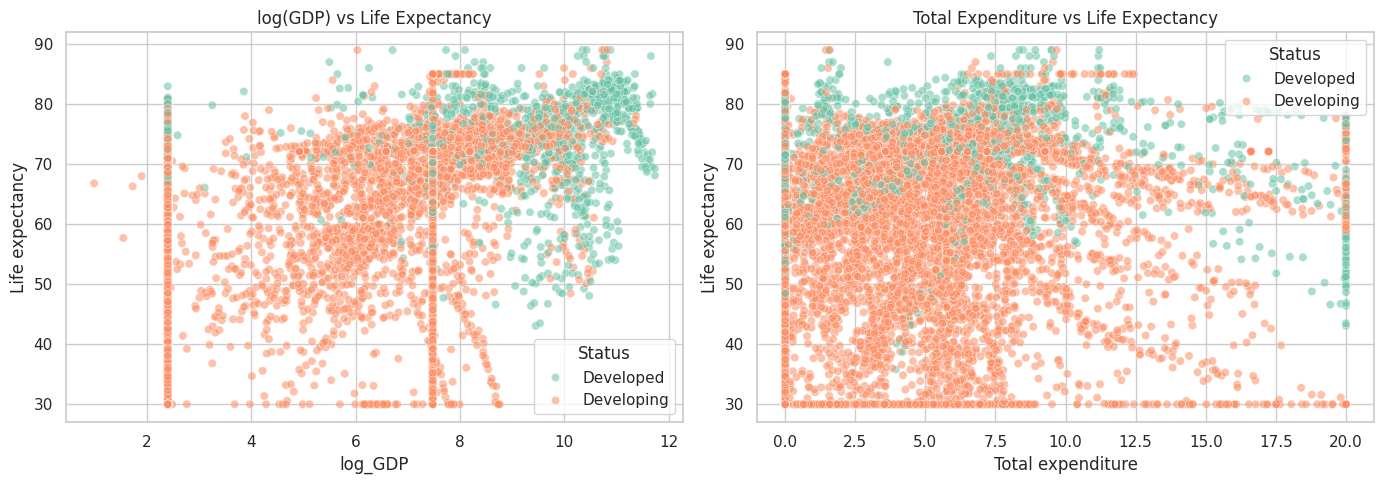

,Life expectancy,GDP,log_GDP,Total expenditure
Life expectancy,1.000,0.299,0.414,0.109
GDP,0.299,1.000,0.583,0.112
log_GDP,0.414,0.583,1.000,0.106
Total expenditure,0.109,0.112,0.106,1.000


In [ ]:
eda_q2['log_GDP'] = np.log1p(eda_q2['GDP'].clip(lower=0))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=eda_q2, x='log_GDP', y='Life expectancy', hue='Status', alpha=0.55, ax=axes[0])
axes[0].set_title('log(GDP) vs Life Expectancy')

sns.scatterplot(data=eda_q2, x='Total expenditure', y='Life expectancy', hue='Status', alpha=0.55, ax=axes[1])
axes[1].set_title('Total Expenditure vs Life Expectancy')
plt.tight_layout()
plt.show()

corr_q2 = eda_q2[['Life expectancy', 'GDP', 'log_GDP', 'Total expenditure']].corr().round(3)
display(corr_q2)

Berdasarkan hasil visualisasi, GDP (terutama setelah dilakukan transformasi log) menunjukkan hubungan positif yang lebih jelas dan cenderung linear terhadap Life Expectancy. Hal ini menunjukkan bahwa distribusi GDP bersifat tidak merata (skewed), sehingga transformasi log membantu dalam memperjelas pola hubungan.

Selain itu, terlihat bahwa negara dengan status Developed cenderung memiliki Life Expectancy yang lebih tinggi dibandingkan Developing.

Total Expenditure juga menunjukkan hubungan positif terhadap Life Expectancy, meskipun tidak sekuat GDP.

Oleh karena itu, variabel-variabel ekonomi dan kesehatan digunakan sebagai fitur dalam model klasifikasi untuk memprediksi status perkembangan negara.

## STEP 6 — Feature & Target

In [ ]:
train = train.dropna(subset=['Status'])

X = train.drop(columns=['Status'])
y = train['Status']

print("Shape X:", X.shape)
print("Shape y:", y.shape)
print("NaN in y:", y.isnull().sum())

Shape X: (10070, 19)
Shape y: (10070,)
NaN in y: 0


## STEP 7 — Split Data

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42
)

## STEP 8 — Modelling

In [ ]:

from xgboost import XGBClassifier

model = XGBClassifier(
    n_estimators=100,
    max_depth=5,
    learning_rate=0.1,
    random_state=42
)

model.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.1, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=5,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=100,
              n_jobs=None, num_parallel_tree=None, ...)

## STEP 9 — Evaluation (F1-score)

In [ ]:
from sklearn.metrics import f1_score, classification_report

y_val_numeric = y_val.astype(int)
y_val_pred = model.predict(X_val).astype(int)


print("\nF1 Score:", f1_score(y_val_numeric, y_val_pred))
print(classification_report(y_val_numeric, y_val_pred))


F1 Score: 0.9961205610265592
              precision    recall  f1-score   support

           0       0.98      0.98      0.98       338
           1       1.00      1.00      1.00      1676

    accuracy                           0.99      2014
   macro avg       0.99      0.99      0.99      2014
weighted avg       0.99      0.99      0.99      2014



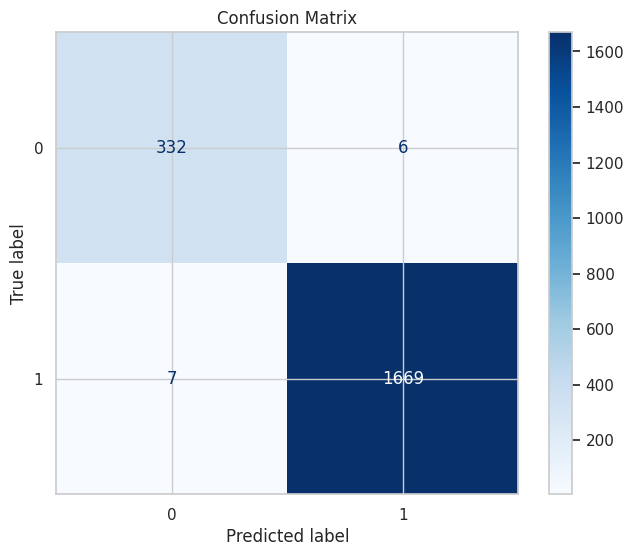

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Generate confusion matrix
cm = confusion_matrix(y_val_numeric, y_val_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=model.classes_)

# Plot
fig, ax = plt.subplots(figsize=(8, 6))
disp.plot(cmap='Blues', ax=ax)
plt.title('Confusion Matrix')
plt.show()

## STEP 10 — Prediksi ke test_cla.csv

In [ ]:
test_pred = model.predict(test)

## Step 11- menyimpan hasil


In [ ]:
submission = pd.DataFrame({
    "id": range(len(test_pred)),
    "Status": test_pred
})

submission.to_csv("submission.csv", index=False)

# TP1 - Status Classification
## Random Forest Model

## Step 1: Load Data & Imports

In [ ]:
# # This Python 3 environment comes with many helpful analytics libraries installed
# # It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# # For example, here's several helpful packages to load

# # import numpy as np # linear algebra
# # import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# # Input data files are available in the read-only "../input/" directory
# # For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# # You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All"
# # You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score, classification_report, confusion_matrix

sns.set_theme(style="whitegrid", palette="Set2")
PALETTE = {"Developed": "#4C72B0", "Developing": "#DD8452"}

In [ ]:
# Load the datasets
try:
    train = pd.read_csv("/kaggle/input/competitions/tp-1-life-expectancy-kasdd-genap-2025-2026/train.csv")
    test  = pd.read_csv("/kaggle/input/competitions/tp-1-life-expectancy-kasdd-genap-2025-2026/test.csv")
except:
    train = pd.read_csv("train.csv")
    test  = pd.read_csv("test.csv")

print(f"Train shape: {train.shape}")
print(f"Test shape: {test.shape}")

Train shape: (10070, 21)
Test shape: (1259, 19)


## Step 2: Data Exploration (EDA)

In [ ]:
# Checks the data
train.head()
print()
train.info()
print()
train.describe().T


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10070 entries, 0 to 10069
Data columns (total 21 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Year                             10070 non-null  int64  
 1   Status                           10070 non-null  object 
 2   Life expectancy                  10062 non-null  float64
 3   Adult Mortality                  10062 non-null  float64
 4   infant deaths                    10070 non-null  int64  
 5   Alcohol                          9920 non-null   float64
 6   percentage expenditure           10070 non-null  float64
 7   Measles                          10070 non-null  int64  
 8   BMI                              10047 non-null  float64
 9   under-five deaths                10070 non-null  int64  
 10  Total expenditure                9894 non-null   float64
 11  GDP                              9707 non-null   float64
 12  thinness  1-19 ye

,count,mean,std,min,25%,50%,75%,max
Year,10070.0,1.982327e+03,1.890324e+01,1950.00000,1966.000000,1982.000000,1.998000e+03,2.015000e+03
Life expectancy,10062.0,6.168606e+01,1.420348e+01,30.00000,53.705956,65.740650,7.210000e+01,8.900000e+01
Adult Mortality,10062.0,2.324526e+02,2.138724e+02,1.00000,93.082183,171.279919,3.000214e+02,1.000000e+03
infant deaths,10070.0,5.213684e+01,2.557956e+02,0.00000,0.000000,4.000000,2.900000e+01,4.840000e+03
Alcohol,9920.0,5.786028e+00,6.134692e+00,0.01000,0.646448,3.970000,8.741190e+00,3.000000e+01
percentage expenditure,10070.0,1.961027e+02,1.003055e+03,0.00000,0.000000,0.000000,1.000000e+02,1.909905e+04
Measles,10070.0,7.723835e+03,3.423361e+04,0.00000,0.000000,35.000000,2.480000e+03,6.388990e+05
BMI,10047.0,3.106347e+01,2.372595e+01,1.00000,6.771506,26.100000,4.990000e+01,8.730000e+01
under-five deaths,10070.0,7.637110e+01,3.609292e+02,0.00000,0.000000,5.000000,4.100000e+01,6.968000e+03
Total expenditure,9894.0,5.321350e+00,4.252678e+00,0.00000,2.385204,4.850228,7.100000e+00,2.000000e+01


In [ ]:
# Checks how many missing values per column
missing = train.isnull().sum()
missing_pct = (missing / len(train) * 100).round(2)

missing_df = pd.DataFrame({"Missing Count": missing, "Missing %": missing_pct})
print(missing_df[missing_df["Missing Count"] > 0].sort_values("Missing %", ascending=False))

                                 Missing Count  Missing %
Population                                 527       5.23
Hepatitis B                                456       4.53
GDP                                        363       3.60
Total expenditure                          176       1.75
Alcohol                                    150       1.49
Income composition of resources            140       1.39
Schooling                                  137       1.36
thinness  1-19 years                        23       0.23
BMI                                         23       0.23
thinness 5-9 years                          23       0.23
Polio                                       13       0.13
Diphtheria                                  13       0.13
Life expectancy                              8       0.08
Adult Mortality                              8       0.08


Target class counts:
Status
Developing    8380
Developed     1690
Name: count, dtype: int64

Target class percentages:
Status
Developing    83.2
Developed     16.8
Name: proportion, dtype: float64


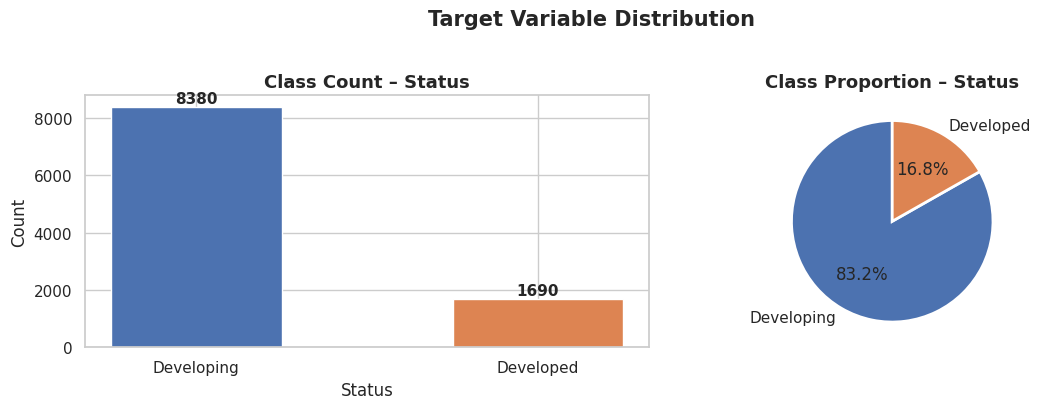

In [ ]:
# Checks target class distribution
print("Target class counts:")
print(train["Status"].value_counts())
print()
print("Target class percentages:")
print(train["Status"].value_counts(normalize=True).round(3) * 100)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Bar chart
counts = train["Status"].value_counts()
bars = axes[0].bar(counts.index, counts.values, color=[PALETTE["Developed"], PALETTE["Developing"]], edgecolor="white", width=0.5)
for bar in bars:
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 30, f"{int(bar.get_height())}", ha="center", va="bottom", fontsize=11, fontweight="bold")
axes[0].set_title("Class Count – Status", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Status"); axes[0].set_ylabel("Count")

# Pie chart
axes[1].pie(counts.values, labels=counts.index, autopct="%1.1f%%", colors=[PALETTE["Developed"], PALETTE["Developing"]], startangle=90, wedgeprops={"edgecolor": "white", "linewidth": 2})
axes[1].set_title("Class Proportion – Status", fontsize=13, fontweight="bold")

plt.suptitle("Target Variable Distribution", fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

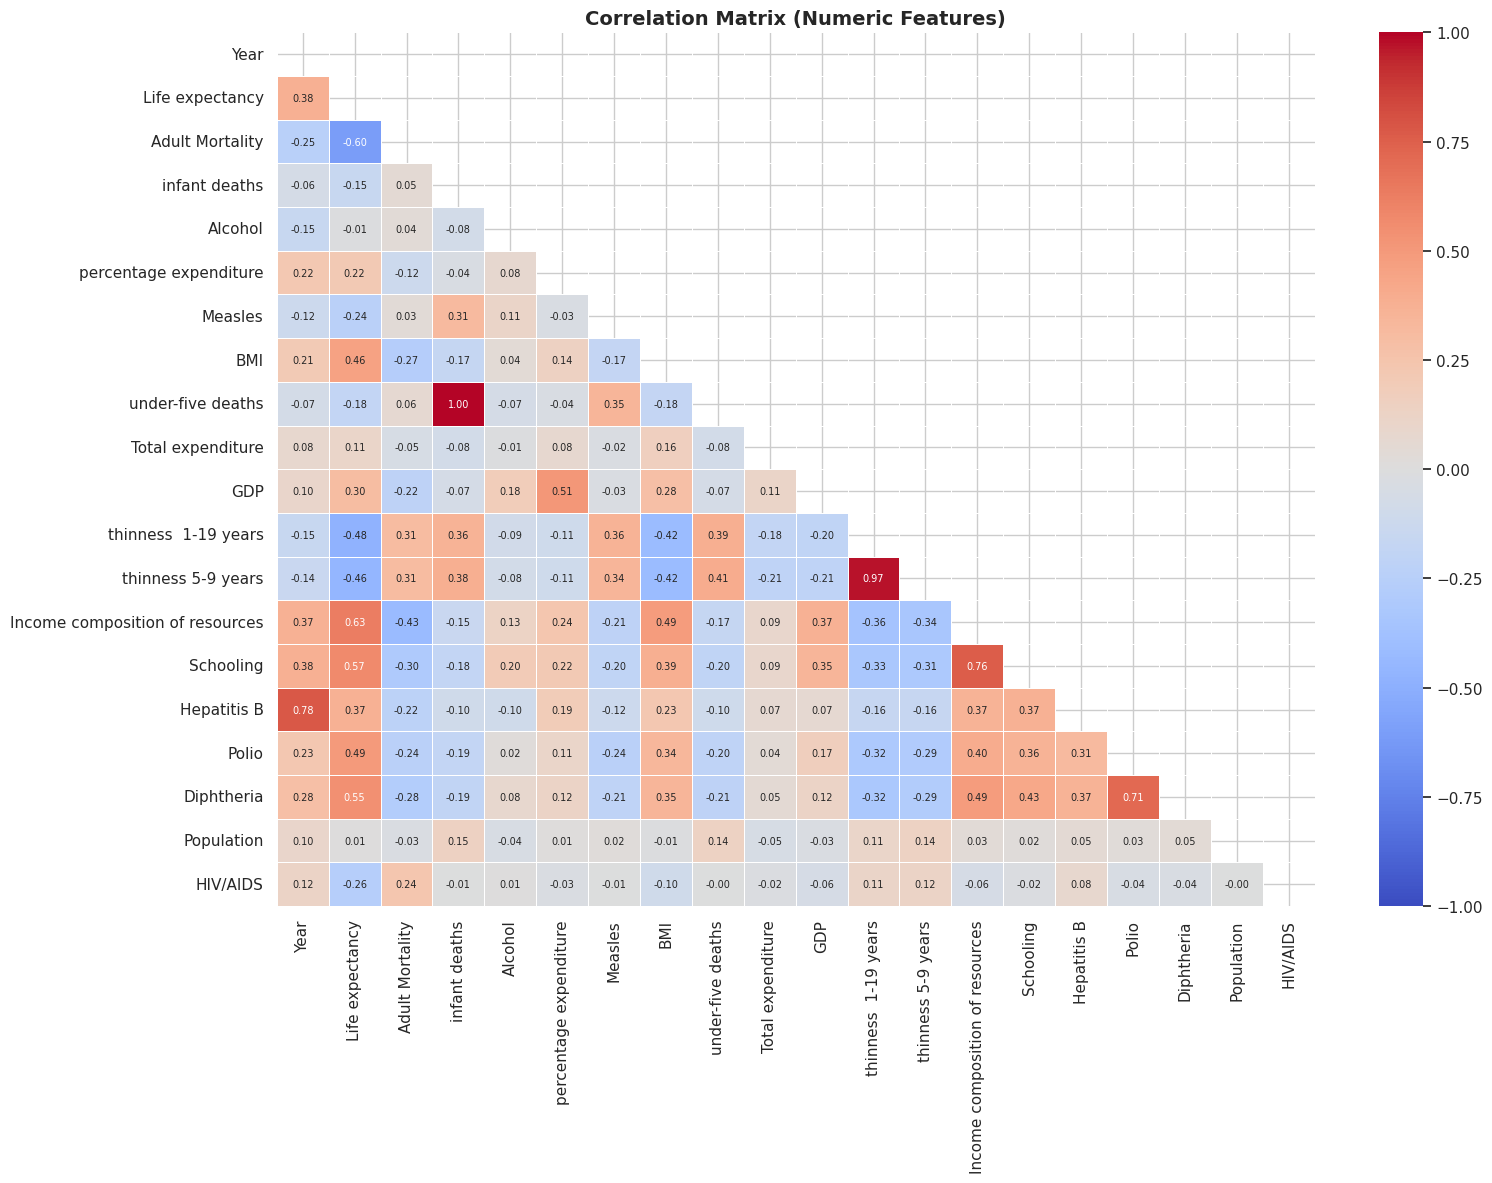

In [ ]:
# Correlation heatmap
num_cols = train.select_dtypes(include=np.number).columns.tolist()

fig, ax = plt.subplots(figsize=(16, 12))
corr = train[num_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap="coolwarm", linewidths=0.5, linecolor="white", ax=ax, annot_kws={"size": 7}, vmin=-1, vmax=1)
ax.set_title("Correlation Matrix (Numeric Features)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

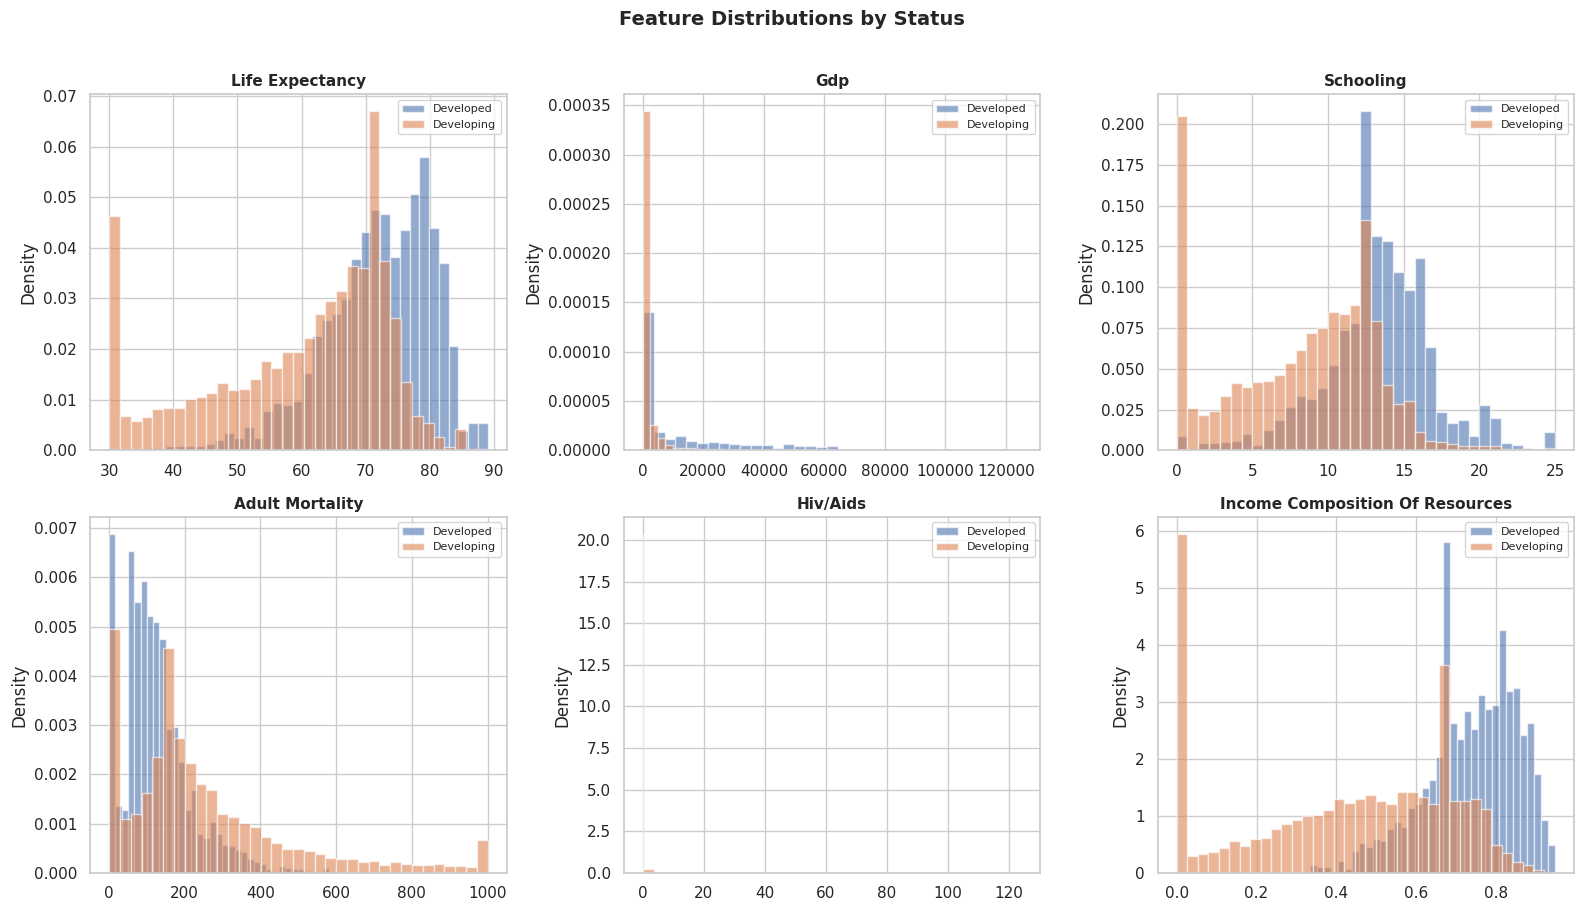

In [ ]:
key_features = ["Life expectancy", "GDP", "Schooling", "Adult Mortality", "HIV/AIDS", "Income composition of resources"]
key_features = [col for col in key_features if col in train.columns]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, feat in enumerate(key_features):
    for label, grp in train.groupby("Status"):
        axes[i].hist(grp[feat].dropna(), bins=35, alpha=0.6, label=label, density=True, color=PALETTE.get(label, "grey"), edgecolor="white")
    axes[i].set_title(feat.replace("_", " ").title(), fontsize=11, fontweight="bold")
    axes[i].set_ylabel("Density")
    axes[i].legend(fontsize=8)

plt.suptitle("Feature Distributions by Status", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

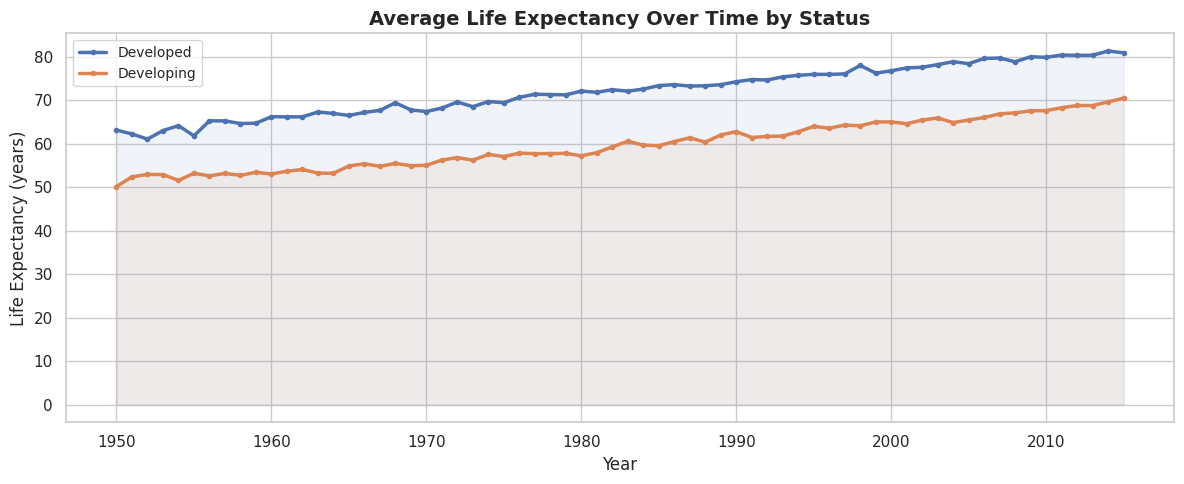

In [ ]:
time_df = train.groupby(["Year", "Status"])["Life expectancy"].mean().reset_index()

fig, ax = plt.subplots(figsize=(12, 5))
for label, grp in time_df.groupby("Status"):
    ax.plot(grp["Year"], grp["Life expectancy"], label=label, color=PALETTE.get(label), linewidth=2.5, marker="o", markersize=3)
    ax.fill_between(grp["Year"], grp["Life expectancy"], alpha=0.08, color=PALETTE.get(label))

ax.set_title("Average Life Expectancy Over Time by Status", fontsize=14, fontweight="bold")
ax.set_xlabel("Year")
ax.set_ylabel("Life Expectancy (years)")
ax.legend(fontsize=10)
plt.tight_layout()
plt.show()

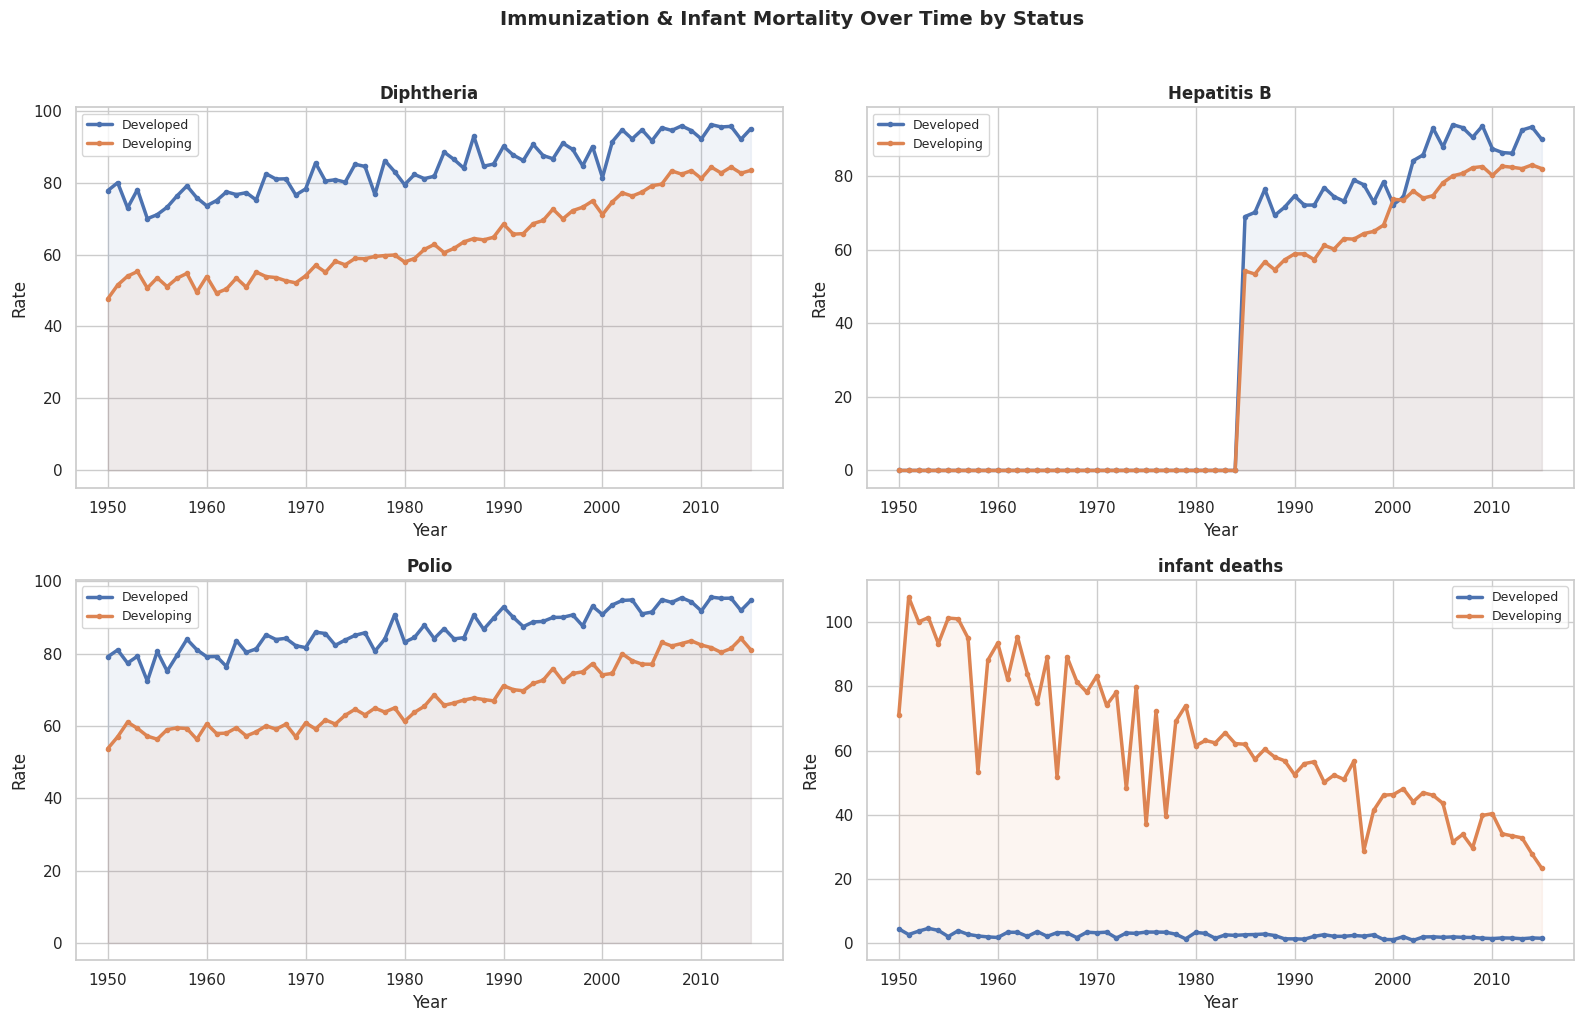

In [ ]:
disease_cols_2 = ["Diphtheria", "Hepatitis B", "Polio", "infant deaths"]

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.flatten()

for ax, col in zip(axes, disease_cols_2):
    disease_df = train.groupby(["Year", "Status"])[col].mean().reset_index()
    for label, grp in disease_df.groupby("Status"):
        ax.plot(grp["Year"], grp[col], label=label, color=PALETTE.get(label), linewidth=2.5, marker="o", markersize=3)
        ax.fill_between(grp["Year"], grp[col], alpha=0.08, color=PALETTE.get(label))
    ax.set_title(col, fontsize=12, fontweight="bold")
    ax.set_xlabel("Year")
    ax.set_ylabel("Rate")
    ax.legend(fontsize=9)

plt.suptitle("Immunization & Infant Mortality Over Time by Status", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

## Step 3: Outlier Cropping

In [ ]:
# Clips data outliers
def clip_outliers(df, exclude_cols=None):
    df = df.copy()
    exclude_cols = exclude_cols or []
    cols = [col for col in df.select_dtypes(include=np.number).columns if col not in exclude_cols]
    for col in cols:
        Q1, Q3 = df[col].quantile(0.25), df[col].quantile(0.75)
        IQR = Q3 - Q1
        df[col] = df[col].clip(Q1 - 1.5 * IQR, Q3 + 1.5 * IQR)
    return df

train_clipped = clip_outliers(train, exclude_cols=["Year"])
test_clipped = clip_outliers(test, exclude_cols=["Year"])

print(f"Old train shape: {train.shape}")
print(f"Old test shape: {test.shape}")
print(f"New train shape: {train_clipped.shape}")
print(f"New test shape: {test_clipped.shape}")

Old train shape: (10070, 21)
Old test shape: (1259, 19)
New train shape: (10070, 21)
New test shape: (1259, 19)


In [ ]:
# Replaces the 0s of pre-1982 Hepatitis B with NaN
def fill_pre1982_hepatitis(train_df, test_df):
    train_df = train_df.copy()
    test_df  = test_df.copy()

    for df in [train_df, test_df]:
        mask = (df["Year"] < 1982) & (df["Hepatitis B"] == 0)
        df.loc[mask, "Hepatitis B"] = np.nan

    return train_df, test_df

train_cleaned, test_cleaned = fill_pre1982_hepatitis(train_clipped, test_clipped)

print(f"Hepatitis B NaNs introduced: {train_cleaned['Hepatitis B'].isnull().sum()}")

Hepatitis B NaNs introduced: 5368


## Step 4: Feature Engineering

In [ ]:
def engineer_features(df):
    df = df.copy()

    # Merge infant deaths & under-five deaths
    if "infant deaths" in df.columns and "under-five deaths" in df.columns:
        df["child_mortality_total"] = df["infant deaths"] + df["under-five deaths"]

    # Average thinness 1-19 & thinness 5-9
    if "thinness  1-19 years" in df.columns and "thinness 5-9 years" in df.columns:
        df["avg_thinness"] = (df["thinness  1-19 years"] + df["thinness 5-9 years"]) / 2

    # Average Polio & Diphtheria
    if "Polio" in df.columns and "Diphtheria" in df.columns:
        df["avg_immunisation"] = (df["Polio"] + df["Diphtheria"]) / 2

    if "percentage expenditure" in df.columns and "GDP" in df.columns:
        df["health_spend_ratio"] = df["percentage expenditure"] / (df["GDP"] + 1)

    # Hepatitis B x Year
    if "Hepatitis B" in df.columns and "Year" in df.columns:
        df["hepatitis_x_year"] = df["Hepatitis B"] * df["Year"]

    # Schooling x Income composition
    if "Schooling" in df.columns and "Income composition of resources" in df.columns:
        df["schooling_x_income"] = df["Schooling"] * df["Income composition of resources"]

    # Adult Mortality x HIV/AIDS
    if "Adult Mortality" in df.columns and "HIV/AIDS" in df.columns:
        df["mortality_x_hiv"] = df["Adult Mortality"] * df["HIV/AIDS"]

    # Log transform GDPs
    if "GDP" in df.columns:
        df["log_gdp"] = np.log1p(df["GDP"].clip(0))

    # Log transform percentage expenditure
    if "percentage expenditure" in df.columns:
        df["log_pct_expenditure"] = np.log1p(df["percentage expenditure"].clip(0))

    cols_to_drop = [
        "infant deaths",  "under-five deaths",
        "thinness  1-19 years", "thinness 5-9 years",
        "Polio", "Diphtheria",
        "GDP", "percentage expenditure",
        "Population"
    ]

    df.drop(columns=cols_to_drop, inplace=True)

    return df

train_fe = engineer_features(train_clipped)
test_fe = engineer_features(test_clipped)

new_cols = [col for col in train_fe.columns if col not in train_clipped.columns]
print(f"New engineered features ({len(new_cols)}):")
for col in new_cols:
    print(f"- {col}")
print(f"\nTrain shape: {train_fe.shape}")
print(f"Test shape: {test_fe.shape}")

New engineered features (9):
- child_mortality_total
- avg_thinness
- avg_immunisation
- health_spend_ratio
- hepatitis_x_year
- schooling_x_income
- mortality_x_hiv
- log_gdp
- log_pct_expenditure

Train shape: (10070, 21)
Test shape: (1259, 19)


## Step 5: Data Preprocessing

In [ ]:
# Separate features and target
y = train_fe["Status"]
X = train_fe.drop(columns=["Status"])

print(f"Features shape: {X.shape}")
print(f"Target shape: {y.shape}")
print(f"\nTarget unique values: {y.unique()}")

Features shape: (10070, 20)
Target shape: (10070,)

Target unique values: ['Developed' 'Developing']


In [ ]:
# Encode the target label
label_map = {"Developing": 1, "Developed": 0}
y_encoded = y.map(label_map)

print("Encoded target distribution:")
print("(0 = Developed, 1 = Developing)")
print(y_encoded.value_counts())

Encoded target distribution:
(0 = Developed, 1 = Developing)
Status
1    8380
0    1690
Name: count, dtype: int64


In [ ]:
# Identify numeric columns
numeric_cols = X.select_dtypes(include=[np.number]).columns.tolist()
print(f"Numeric columns ({len(numeric_cols)}):")
print(numeric_cols)

Numeric columns (20):
['Year', 'Life expectancy', 'Adult Mortality', 'Alcohol', 'Measles', 'BMI', 'Total expenditure', 'Income composition of resources', 'Schooling', 'Hepatitis B', 'HIV/AIDS', 'child_mortality_total', 'avg_thinness', 'avg_immunisation', 'health_spend_ratio', 'hepatitis_x_year', 'schooling_x_income', 'mortality_x_hiv', 'log_gdp', 'log_pct_expenditure']


In [ ]:
# Fill missing values
imputer = SimpleImputer(strategy="median")

X_imputed = pd.DataFrame(imputer.fit_transform(X[numeric_cols]), columns=numeric_cols)

print(f"Missing values after imputation: {X_imputed.isnull().sum().sum()}")

Missing values after imputation: 0


In [ ]:
# Scaling
# scaler = StandardScaler()
# X_scaled = scaler.fit_transform(X_imputed)

# print(f"Scaled features shape: {X_scaled.shape}")

## Step 6: Random Forest Model Training

In [ ]:
# Split data into training and validation sets
X_train, X_val, y_train, y_val = train_test_split(X_imputed, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded)

print(f"Training samples: {X_train.shape[0]}")
print(f"Validation samples: {X_val.shape[0]}")

Training samples: 8056
Validation samples: 2014


In [ ]:
# Train the Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=750,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

RandomForestClassifier(class_weight='balanced', n_estimators=750, n_jobs=-1,
                       random_state=42)

## Step 7: Model Evaluation

In [ ]:
# Predict on the validation set
y_val_pred = rf_model.predict(X_val)

# Calculate F1-score
f1 = f1_score(y_val, y_val_pred)
print(f"Validation F1-Score: {f1:.4f}")
print()
print("Full Classification Report:")
print(classification_report(y_val, y_val_pred, target_names=["Developed (0)", "Developing (1)"]))

Validation F1-Score: 0.9976

Full Classification Report:
                precision    recall  f1-score   support

 Developed (0)       0.99      0.99      0.99       338
Developing (1)       1.00      1.00      1.00      1676

      accuracy                           1.00      2014
     macro avg       0.99      0.99      0.99      2014
  weighted avg       1.00      1.00      1.00      2014



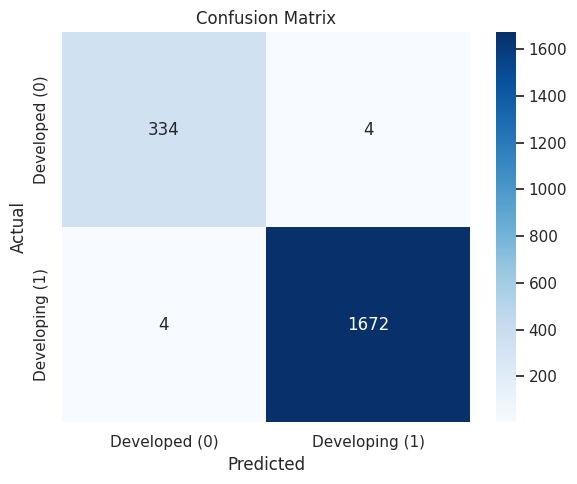

In [ ]:
# Confusion matrix
cm = confusion_matrix(y_val, y_val_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Developed (0)", "Developing (1)"], yticklabels=["Developed (0)", "Developing (1)"])
plt.title("Confusion Matrix")
plt.ylabel("Actual")
plt.xlabel("Predicted")
plt.tight_layout()
plt.show()

In [ ]:
# Cross validation score
cv_scores = cross_val_score(rf_model, X_imputed, y_encoded, cv=5, scoring="f1")
print(f"Cross-Validation F1 Scores: {cv_scores.round(4)}")
print(f"Mean CV F1-Score: {cv_scores.mean():.4f} (+/- {cv_scores.std() * 2:.4f})")

Cross-Validation F1 Scores: [0.9973 0.997  0.9979 0.9964 0.9955]
Mean CV F1-Score: 0.9968 (+/- 0.0016)


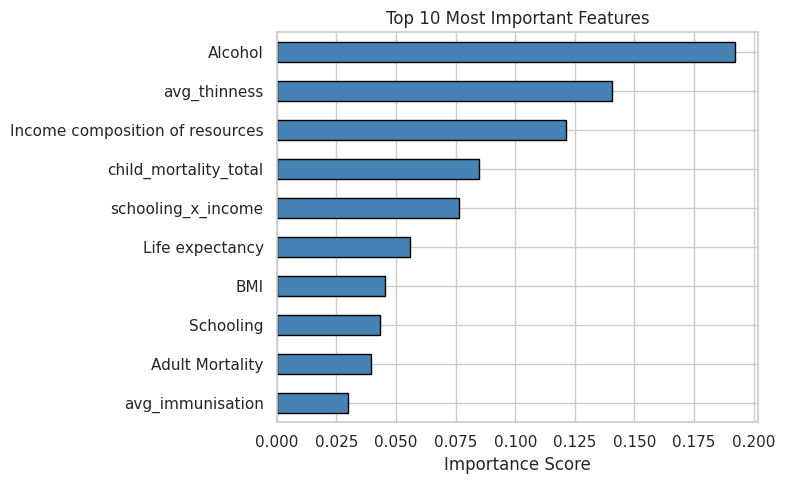

In [ ]:
# Feature importance
importances = pd.Series(rf_model.feature_importances_, index=numeric_cols)
top_features = importances.sort_values(ascending=False).head(10)

plt.figure(figsize=(8, 5))
top_features.sort_values().plot(kind="barh", color="steelblue", edgecolor="black")
plt.title("Top 10 Most Important Features")
plt.xlabel("Importance Score")
plt.tight_layout()
plt.show()

## Step 8: Preprocess Test Data & Make Predictions

In [ ]:
# Preprocessing
shared_cols = [col for col in numeric_cols if col in test_fe.columns]
print(f"Columns in train but not in test (dropped): {[col for col in numeric_cols if col not in test_fe.columns]}")
print(f"Shared columns: {len(shared_cols)}")

imputer_test = SimpleImputer(strategy="median")
scaler_test = StandardScaler()

X_shared = X[shared_cols]
X_shared_imputed = pd.DataFrame(imputer_test.fit_transform(X_shared), columns=shared_cols)
# X_shared_scaled = scaler_test.fit_transform(X_shared_imputed)

test_imputed = pd.DataFrame(imputer_test.transform(test_fe[shared_cols]), columns=shared_cols)
# test_scaled = scaler_test.transform(test_imputed)

print(f"Test data shape after preprocessing: {test_imputed.shape}")

Columns in train but not in test (dropped): ['Life expectancy']
Shared columns: 19
Test data shape after preprocessing: (1259, 19)


In [ ]:
# Retrain on full training data before predicting
rf_final = RandomForestClassifier(
    n_estimators=750,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_final.fit(X_shared_imputed, y_encoded)

test_predictions = rf_final.predict(test_imputed)
print(f"Predictions shape: {test_predictions.shape}")
print(f"Prediction distribution:")
print(pd.Series(test_predictions).value_counts().rename({0: "Developed (0)", 1: "Developing (1)"}))

Predictions shape: (1259,)
Prediction distribution:
Developing (1)    1047
Developed (0)      212
Name: count, dtype: int64


## Step 9: Create Submission File

In [ ]:
# Create and save submission.csv
submission = pd.DataFrame({
    "id": range(len(test_predictions)),
    "Status": test_predictions
})

submission.to_csv("submission_randomforest.csv", index=False)

print(f"Shape: {submission.shape}")
print()
print("First 10 rows:")
print(submission.head(10))
print()
print("Label distribution:")
print(submission["Status"].value_counts())

Shape: (1259, 2)

First 10 rows:
   id  Status
0   0       1
1   1       1
2   2       1
3   3       1
4   4       1
5   5       1
6   6       1
7   7       1
8   8       1
9   9       0

Label distribution:
Status
1    1047
0     212
Name: count, dtype: int64


# TP1 - Status Classification
## CatBoost Model

## I. Setup

### 1.0 Default From Kaggle

In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

# import numpy as np # linear algebra
# import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All"
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

### 1.1 Import Libraries

In [ ]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

### 1.2 Load Dataset

In [ ]:
# Load the datasets
try:
    df_eda = pd.read_csv("/kaggle/input/competitions/tp-1-life-expectancy-kasdd-genap-2025-2026/train.csv")
    df_test_full = pd.read_csv("/kaggle/input/competitions/tp-1-life-expectancy-kasdd-genap-2025-2026/test.csv")
except:
    df_eda = pd.read_csv("train.csv")
    df_test_full = pd.read_csv("test.csv")

## II. Data Understanding and Exploratory Data Analysis (EDA)

### 2.1 Data size

In [ ]:
rows, cols = df_eda.shape
print(f'Jumlah data: {rows}')
print(f'Jumlah fitur: {cols}')

Jumlah data: 10070
Jumlah fitur: 21


### 2.2 Data type and Non-Null Data

In [ ]:
df_eda.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10070 entries, 0 to 10069
Data columns (total 21 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Year                             10070 non-null  int64  
 1   Status                           10070 non-null  object 
 2   Life expectancy                  10062 non-null  float64
 3   Adult Mortality                  10062 non-null  float64
 4   infant deaths                    10070 non-null  int64  
 5   Alcohol                          9920 non-null   float64
 6   percentage expenditure           10070 non-null  float64
 7   Measles                          10070 non-null  int64  
 8   BMI                              10047 non-null  float64
 9   under-five deaths                10070 non-null  int64  
 10  Total expenditure                9894 non-null   float64
 11  GDP                              9707 non-null   float64
 12  thinness  1-19 yea

In [ ]:
df_test_full.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1259 entries, 0 to 1258
Data columns (total 19 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Year                             1259 non-null   int64  
 1   Adult Mortality                  1257 non-null   float64
 2   infant deaths                    1259 non-null   int64  
 3   Alcohol                          1232 non-null   float64
 4   percentage expenditure           1259 non-null   float64
 5   Measles                          1259 non-null   int64  
 6   BMI                              1254 non-null   float64
 7   under-five deaths                1259 non-null   int64  
 8   Total expenditure                1229 non-null   float64
 9   GDP                              1216 non-null   float64
 10  thinness  1-19 years             1254 non-null   float64
 11  thinness 5-9 years               1254 non-null   float64
 12  Income composition o

### 2.3 Descriptive Statistics (Numerical and Categorical)

In [ ]:
# Ringkasan statistik fitur numerik
display(df_eda.describe().T)

,count,mean,std,min,25%,50%,75%,max
Year,10070.0,1.982327e+03,1.890324e+01,1950.00000,1966.000000,1982.000000,1.998000e+03,2.015000e+03
Life expectancy,10062.0,6.168606e+01,1.420348e+01,30.00000,53.705956,65.740650,7.210000e+01,8.900000e+01
Adult Mortality,10062.0,2.324526e+02,2.138724e+02,1.00000,93.082183,171.279919,3.000214e+02,1.000000e+03
infant deaths,10070.0,5.213684e+01,2.557956e+02,0.00000,0.000000,4.000000,2.900000e+01,4.840000e+03
Alcohol,9920.0,5.786028e+00,6.134692e+00,0.01000,0.646448,3.970000,8.741190e+00,3.000000e+01
percentage expenditure,10070.0,1.961027e+02,1.003055e+03,0.00000,0.000000,0.000000,1.000000e+02,1.909905e+04
Measles,10070.0,7.723835e+03,3.423361e+04,0.00000,0.000000,35.000000,2.480000e+03,6.388990e+05
BMI,10047.0,3.106347e+01,2.372595e+01,1.00000,6.771506,26.100000,4.990000e+01,8.730000e+01
under-five deaths,10070.0,7.637110e+01,3.609292e+02,0.00000,0.000000,5.000000,4.100000e+01,6.968000e+03
Total expenditure,9894.0,5.321350e+00,4.252678e+00,0.00000,2.385204,4.850228,7.100000e+00,2.000000e+01


In [ ]:
# Ringkasan statistik fitur kategorikal
cat_desc = df_eda.describe(include=['object']).T
if not cat_desc.empty:
    display(cat_desc)
else:
    print('Tidak ada fitur kategorikal.')

,count,unique,top,freq
Status,10070,2,Developing,8380


Cuma ada satu variabel non-numerik dan variabel tersebut adalah variabel target

In [ ]:
# Statistik untuk fitur lainnya
focus_cols = ['Life expectancy', 'Total expenditure', 'percentage expenditure', 'GDP', 'Income composition of resources', 'Schooling']
focus_cols = [c for c in focus_cols if c in df_eda.columns]

summary_rows = []
for col in focus_cols:
    s = df_eda[col].dropna()
    iqr = s.quantile(0.75) - s.quantile(0.25)
    cv = s.std() / s.mean() if s.mean() != 0 else np.nan
    summary_rows.append({
        'feature': col,
        'mean': s.mean(),
        'median': s.median(),
        'mode': s.mode().iloc[0] if not s.mode().empty else np.nan,
        'std': s.std(),
        'min': s.min(),
        'q1': s.quantile(0.25),
        'q3': s.quantile(0.75),
        'iqr': iqr,
        'max': s.max(),
        'range': s.max() - s.min(),
        'skewness': s.skew(),
        'kurtosis': s.kurt(),
        'coef_var': cv
    })

summary_df = pd.DataFrame(summary_rows)
display(summary_df)

,feature,mean,median,mode,std,min,q1,q3,iqr,max,range,skewness,kurtosis,coef_var
0,Life expectancy,61.686064,65.740650,30.0,14.203480,30.00000,53.705956,72.100000,18.394044,89.000000,59.000000,-0.814825,-0.231248,0.230254
1,Total expenditure,5.321350,4.850228,0.0,4.252678,0.00000,2.385204,7.100000,4.714796,20.000000,20.000000,1.226778,1.947479,0.799173
2,percentage expenditure,196.102675,0.000000,0.0,1003.054608,0.00000,0.000000,100.000000,100.000000,19099.045060,19099.045060,9.758529,117.844912,5.114946
3,GDP,4303.474007,168.648254,10.0,12154.796976,1.68135,10.000000,1766.947595,1756.947595,125097.788731,125096.107381,4.718354,26.716303,2.824415
4,Income composition of resources,0.479002,0.539363,0.0,0.267276,0.00000,0.293527,0.679000,0.385473,0.948000,0.948000,-0.515077,-0.890881,0.557985
5,Schooling,9.044535,10.106075,0.0,5.145238,0.00000,5.355685,12.569284,7.213599,25.000000,25.000000,-0.273275,-0.528412,0.568878


Kolom `Total expenditure`, `percentage expenditure`, dan `thinness 1-19 years` tidak benar-benar merepresentasikan deskripsi asli kolomnya:
- `percentage expenditure`: Pengeluaran kesehatan sebagai persentase dari GDP per kapita (%).
- `Total expenditure`: Pengeluaran kesehatan pemerintah sebagai persentase dari total pengeluaran pemerintah (%).
- `thinness 1-19 years`: Prevalensi kekurusan pada remaja usia 10-19 tahun (%).



Deskripsi semua kolom:
- `Year`: Tahun pengamatan data (1950-2015).
- `Population`: Jumlah populasi negara.
- `Life expectancy`: Harapan hidup dalam satuan tahun.
- `Adult Mortality`: Tingkat kematian dewasa (rentang usia 15-60 tahun) per 1000 populasi.
- `infant deaths`: Jumlah kematian bayi per 1000 populasi.
- `under-five deaths`: Jumlah kematian anak di bawah 5 tahun per 1000 populasi.
- `HIV/AIDS`: Kematian akibat HIV/AIDS per 1000 kelahiran hidup (usia 0-4 tahun).
- `Measles`: Jumlah kasus penyakit campak yang dilaporkan per 1000 populasi.
- `Hepatitis B`: Persentase cakupan imunisasi Hepatitis B pada anak usia 1 tahun (%).
- `Polio`: Persentase cakupan imunisasi Polio pada anak usia 1 tahun (%).
- `Diphtheria`: Persentase cakupan imunisasi DTP3 (Difteri-Tetanus-Pertusis) pada anak usia 1 tahun (%).
- `Alcohol`: Konsumsi alkohol per kapita (liter alkohol murni per orang dengan usia 15+ tahun).
- `BMI`: Body Mass Index rata-rata populasi.
- `thinness 1-19 years`: Prevalensi kekurusan pada remaja usia 10-19 tahun (%).
- `thinness 5-9 years`: Prevalensi kekurusan pada anak usia 5-9 tahun (%).
- `GDP`: Gross Domestic Product per kapita dalam USD.
- `percentage expenditure`: Pengeluaran kesehatan sebagai persentase dari GDP per kapita (%).
- `Total expenditure`: Pengeluaran kesehatan pemerintah sebagai persentase dari total pengeluaran pemerintah (%).
- `Schooling`: Rata-rata lama sekolah atau pendidikan dalam satuan tahun.
- `Income composition of resources`: Indeks Human Development Index dalam hal komposisi pendapatan sumber daya (menggunakan skala 0-1).


### 2.4 Missing Values Analysis

In [ ]:
# Cari kolom dengan missing values dan persentasenya
missing_values = df_eda.isna().sum().reset_index()
missing_values.columns = ['feature', 'missing_count']
missing_values['percentage'] = (missing_values['missing_count'] / len(df_eda)) * 100
print("Kolom dengan Missing Values:")
print(missing_values)

Kolom dengan Missing Values:
                            feature  missing_count  percentage
0                              Year              0    0.000000
1                            Status              0    0.000000
2                   Life expectancy              8    0.079444
3                   Adult Mortality              8    0.079444
4                     infant deaths              0    0.000000
5                           Alcohol            150    1.489573
6            percentage expenditure              0    0.000000
7                           Measles              0    0.000000
8                               BMI             23    0.228401
9                 under-five deaths              0    0.000000
10                Total expenditure            176    1.747766
11                              GDP            363    3.604767
12             thinness  1-19 years             23    0.228401
13               thinness 5-9 years             23    0.228401
14  Income composition of 

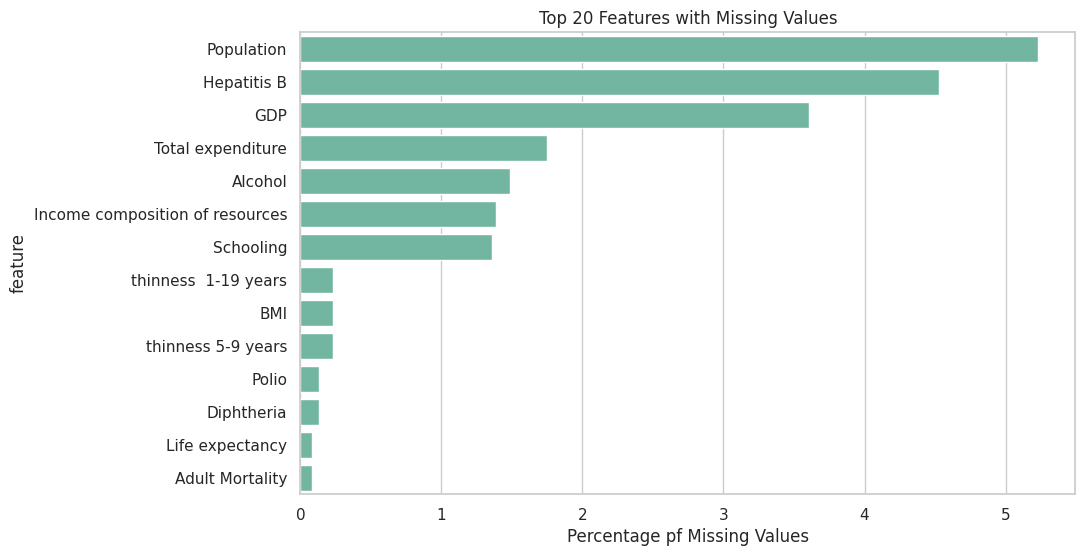

In [ ]:
missing_values = missing_values[missing_values['missing_count'] > 0].sort_values(by='percentage', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x='percentage', y='feature', data=missing_values.head(20))
plt.title('Top 20 Features with Missing Values')
plt.xlabel('Percentage pf Missing Values')
plt.show()

persentase missing values di setiap kolomnya selalu <20, berarti semuanya bisa diimpute

### 2.5 Life Expectancy Trend in 2000-2015 for Developed and Developing Countries

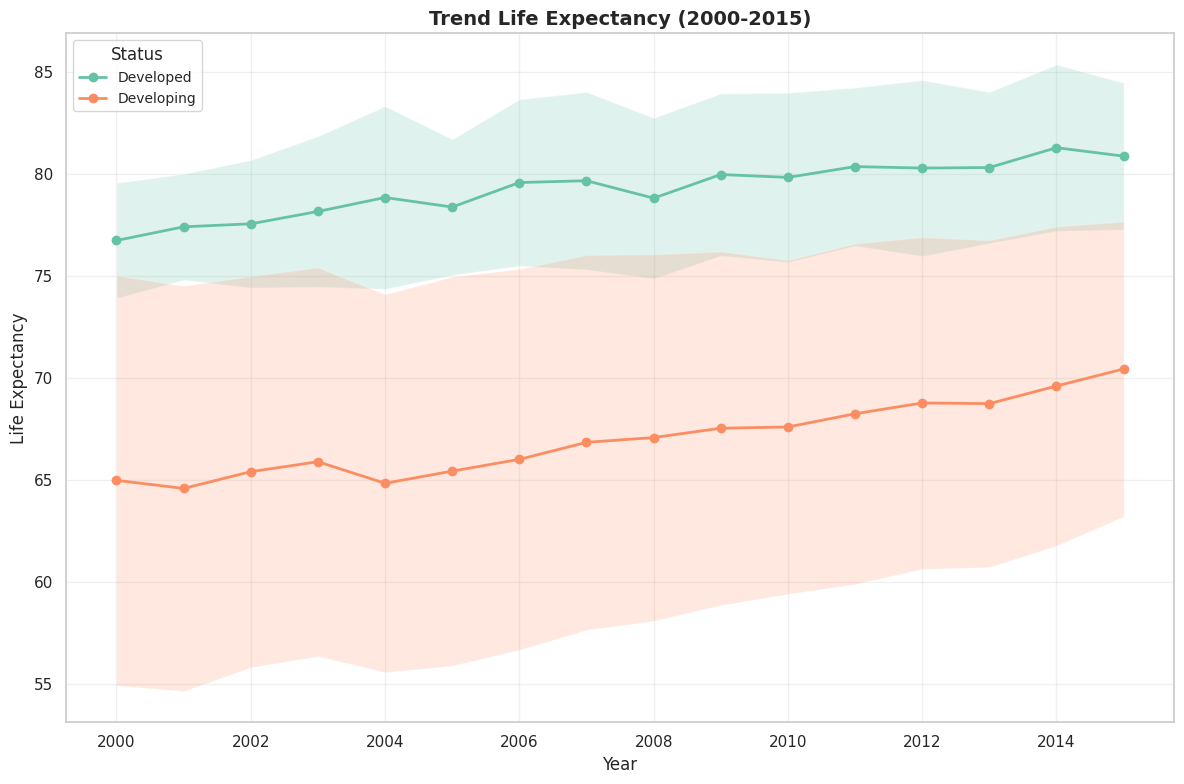

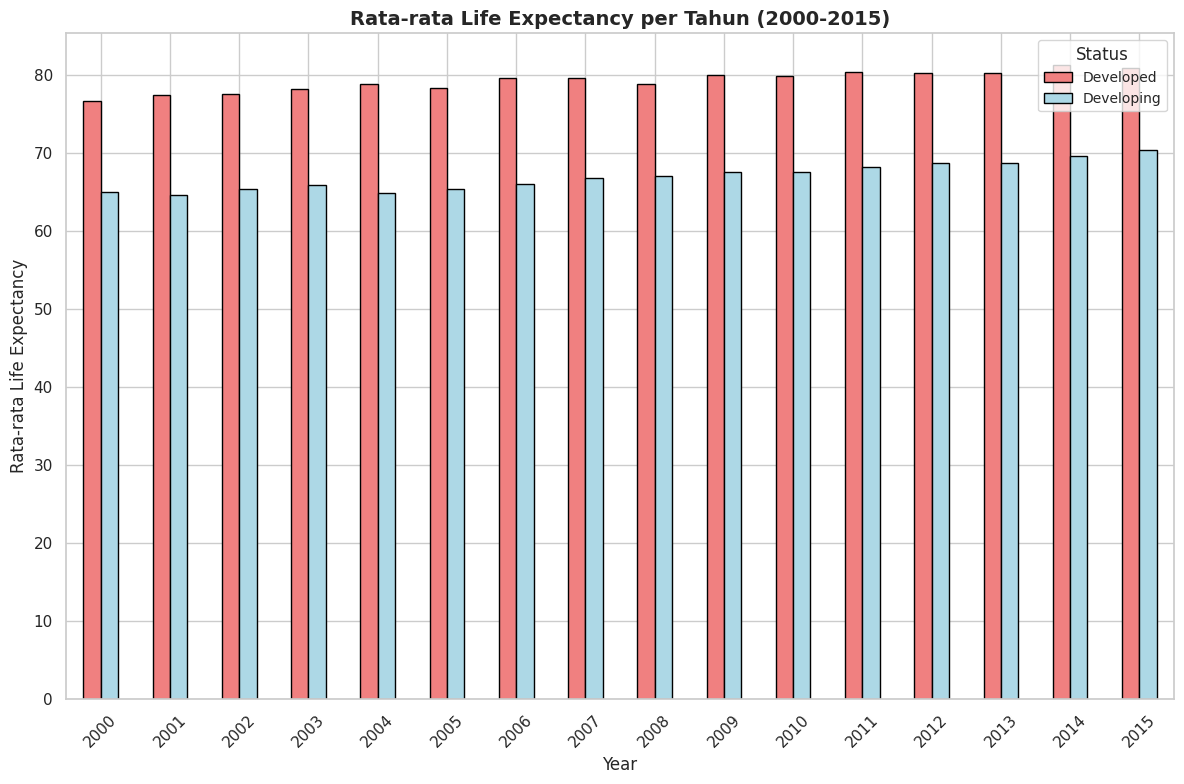

In [ ]:
# Filter data untuk tahun 2000-2015
df_2000_2015 = df_eda[(df_eda['Year'] >= 2000) & (df_eda['Year'] <= 2015)]

# 4.1 Line plot: Trend Life Expectancy per tahun
yearly_stats = df_2000_2015.groupby(['Year', 'Status'])['Life expectancy'].agg(['mean', 'std']).reset_index()

fig1, ax1 = plt.subplots(figsize=(12, 8))
for status in ['Developed', 'Developing']:
    subset = yearly_stats[yearly_stats['Status'] == status]
    ax1.plot(subset['Year'], subset['mean'], marker='o', linewidth=2, label=status)
    ax1.fill_between(subset['Year'],
                     subset['mean'] - subset['std'],
                     subset['mean'] + subset['std'],
                     alpha=0.2)

ax1.set_xlabel('Year', fontsize=12)
ax1.set_ylabel('Life Expectancy', fontsize=12)
ax1.set_title('Trend Life Expectancy (2000-2015)', fontsize=14, fontweight='bold')
ax1.legend(title='Status', fontsize=10)
ax1.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 4.2 Bar plot: Rata-rata Life Expectancy per tahun
pivot_data = yearly_stats.pivot(index='Year', columns='Status', values='mean')

fig2, ax2 = plt.subplots(figsize=(12, 8))
pivot_data.plot(kind='bar', ax=ax2, color=['lightcoral', 'lightblue'], edgecolor='black')
ax2.set_xlabel('Year', fontsize=12)
ax2.set_ylabel('Rata-rata Life Expectancy', fontsize=12)
ax2.set_title('Rata-rata Life Expectancy per Tahun (2000-2015)', fontsize=14, fontweight='bold')
ax2.legend(title='Status', fontsize=10)
ax2.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
# Analisis statistik
print("\nAnalisis Statistik:")
print("-" * 50)

# Rata-rata Life Expectancy per tahun dan status
print("Rata-rata Life Expectancy per Tahun dan Status:")
yearly_mean = df_2000_2015.groupby(['Year', 'Status'])['Life expectancy'].mean().unstack()
print(yearly_mean)

# Rata-rata keseluruhan
print(f"\nRata-rata Life Expectancy (2000-2015):")
overall_mean = df_2000_2015.groupby('Status')['Life expectancy'].agg(['mean', 'std', 'min', 'max'])
print(overall_mean)

# Trend analysis menggunakan regresi linear
print(f"\nTrend Analysis (Regresi Linear):")
for status in ['Developed', 'Developing']:
    subset = df_2000_2015[df_2000_2015['Status'] == status]
    yearly_avg = subset.groupby('Year')['Life expectancy'].mean()

    slope, intercept, r_value, p_value, std_err = stats.linregress(yearly_avg.index, yearly_avg.values)
    print(f"\n{status}:")
    print(f"  Slope: {slope:.4f} (perubahan per tahun)")
    print(f"  R-squared: {r_value**2:.4f}")
    print(f"  P-value: {p_value:.6f}")
    print(f"  Signifikan (alpha=0.05): {'Ya' if p_value < 0.05 else 'Tidak'}")


Analisis Statistik:
--------------------------------------------------
Rata-rata Life Expectancy per Tahun dan Status:
Status  Developed  Developing
Year                         
2000    76.733333   64.971545
2001    77.403571   64.575610
2002    77.550000   65.396581
2003    78.156000   65.883193
2004    78.840000   64.828571
2005    78.372000   65.423333
2006    79.574074   66.000000
2007    79.664000   66.835433
2008    78.807407   67.069748
2009    79.967857   67.527731
2010    79.826667   67.588696
2011    80.356522   68.236719
2012    80.284000   68.766393
2013    80.310714   68.733613
2014    81.282609   69.597479
2015    80.869231   70.433333

Rata-rata Life Expectancy (2000-2015):
                 mean       std   min   max
Status                                     
Developed   79.244686  3.931540  71.0  89.0
Developing  66.983428  9.039806  39.0  89.0

Trend Analysis (Regresi Linear):

Developed:
  Slope: 0.2650 (perubahan per tahun)
  R-squared: 0.9092
  P-value: 0.000000


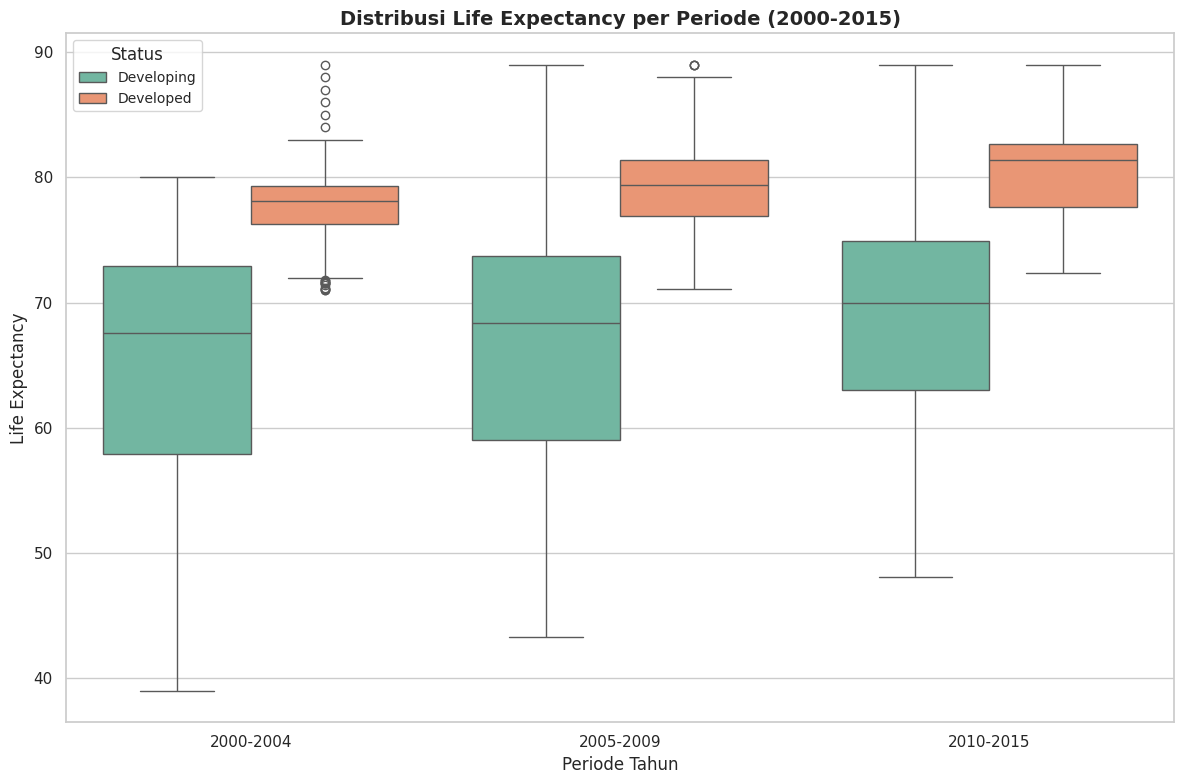

In [ ]:
# 4.3 Box plot: Distribusi Life Expectancy per 5 tahun
df_2000_2015['Year_Group'] = pd.cut(df_2000_2015['Year'],
                                      bins=[1999, 2004, 2009, 2015],
                                      labels=['2000-2004', '2005-2009', '2010-2015'])

fig3, ax3 = plt.subplots(figsize=(12, 8))
sns.boxplot(data=df_2000_2015, x='Year_Group', y='Life expectancy', hue='Status',
            ax=ax3, palette='Set2')
ax3.set_xlabel('Periode Tahun', fontsize=12)
ax3.set_ylabel('Life Expectancy', fontsize=12)
ax3.set_title('Distribusi Life Expectancy per Periode (2000-2015)', fontsize=14, fontweight='bold')
ax3.legend(title='Status', fontsize=10)
plt.tight_layout()
plt.show()

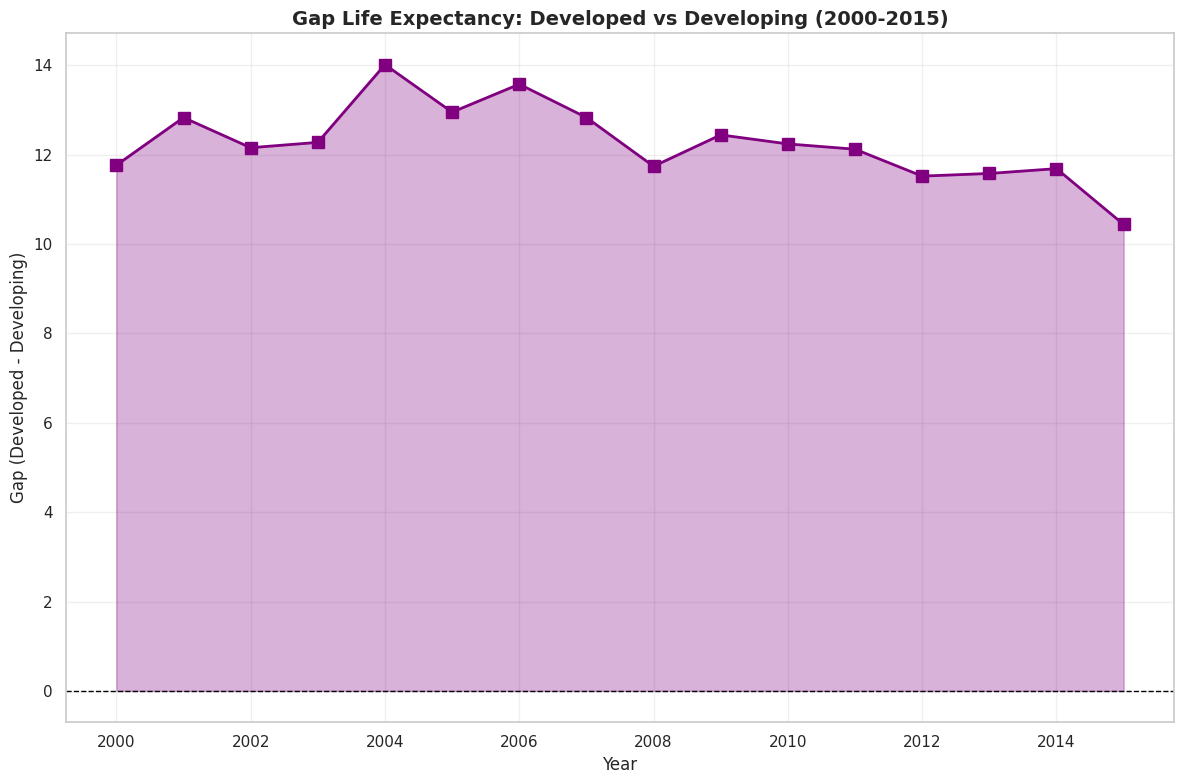


Gap Life Expectancy (Developed - Developing):
Year
2000    11.761789
2001    12.827962
2002    12.153419
2003    12.272807
2004    14.011429
2005    12.948667
2006    13.574074
2007    12.828567
2008    11.737660
2009    12.440126
2010    12.237971
2011    12.119803
2012    11.517607
2013    11.577101
2014    11.685130
2015    10.435897
dtype: float64

Rata-rata Gap: 12.26
Gap Minimum: 10.44 (Tahun 2015)
Gap Maksimum: 14.01 (Tahun 2004)


In [ ]:
# 4.4 Line plot: Gap antara Developed dan Developing
gap_data = yearly_stats.pivot(index='Year', columns='Status', values='mean')
gap_data['Gap'] = gap_data['Developed'] - gap_data['Developing']

fig4, ax4 = plt.subplots(figsize=(12, 8))
ax4.plot(gap_data.index, gap_data['Gap'], marker='s', linewidth=2, color='purple', markersize=8)
ax4.axhline(y=0, color='black', linestyle='--', linewidth=1)
ax4.fill_between(gap_data.index, 0, gap_data['Gap'], alpha=0.3, color='purple')
ax4.set_xlabel('Year', fontsize=12)
ax4.set_ylabel('Gap (Developed - Developing)', fontsize=12)
ax4.set_title('Gap Life Expectancy: Developed vs Developing (2000-2015)', fontsize=14, fontweight='bold')
ax4.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Gap analysis
gap_data = yearly_mean['Developed'] - yearly_mean['Developing']
print(f"\nGap Life Expectancy (Developed - Developing):")
print(gap_data)
print(f"\nRata-rata Gap: {gap_data.mean():.2f}")
print(f"Gap Minimum: {gap_data.min():.2f} (Tahun {gap_data.idxmin()})")
print(f"Gap Maksimum: {gap_data.max():.2f} (Tahun {gap_data.idxmax()})")

**RINGKASAN ANALISIS**

Trend Life Expectancy 2000-2015:
- Life Expectancy meningkat untuk kedua kategori negara
- Gap antara Developed dan Developing cenderung menurun
- Negara Developing menunjukkan peningkatan yang lebih cepat

### 2.6 Heatmap of Features Correlation

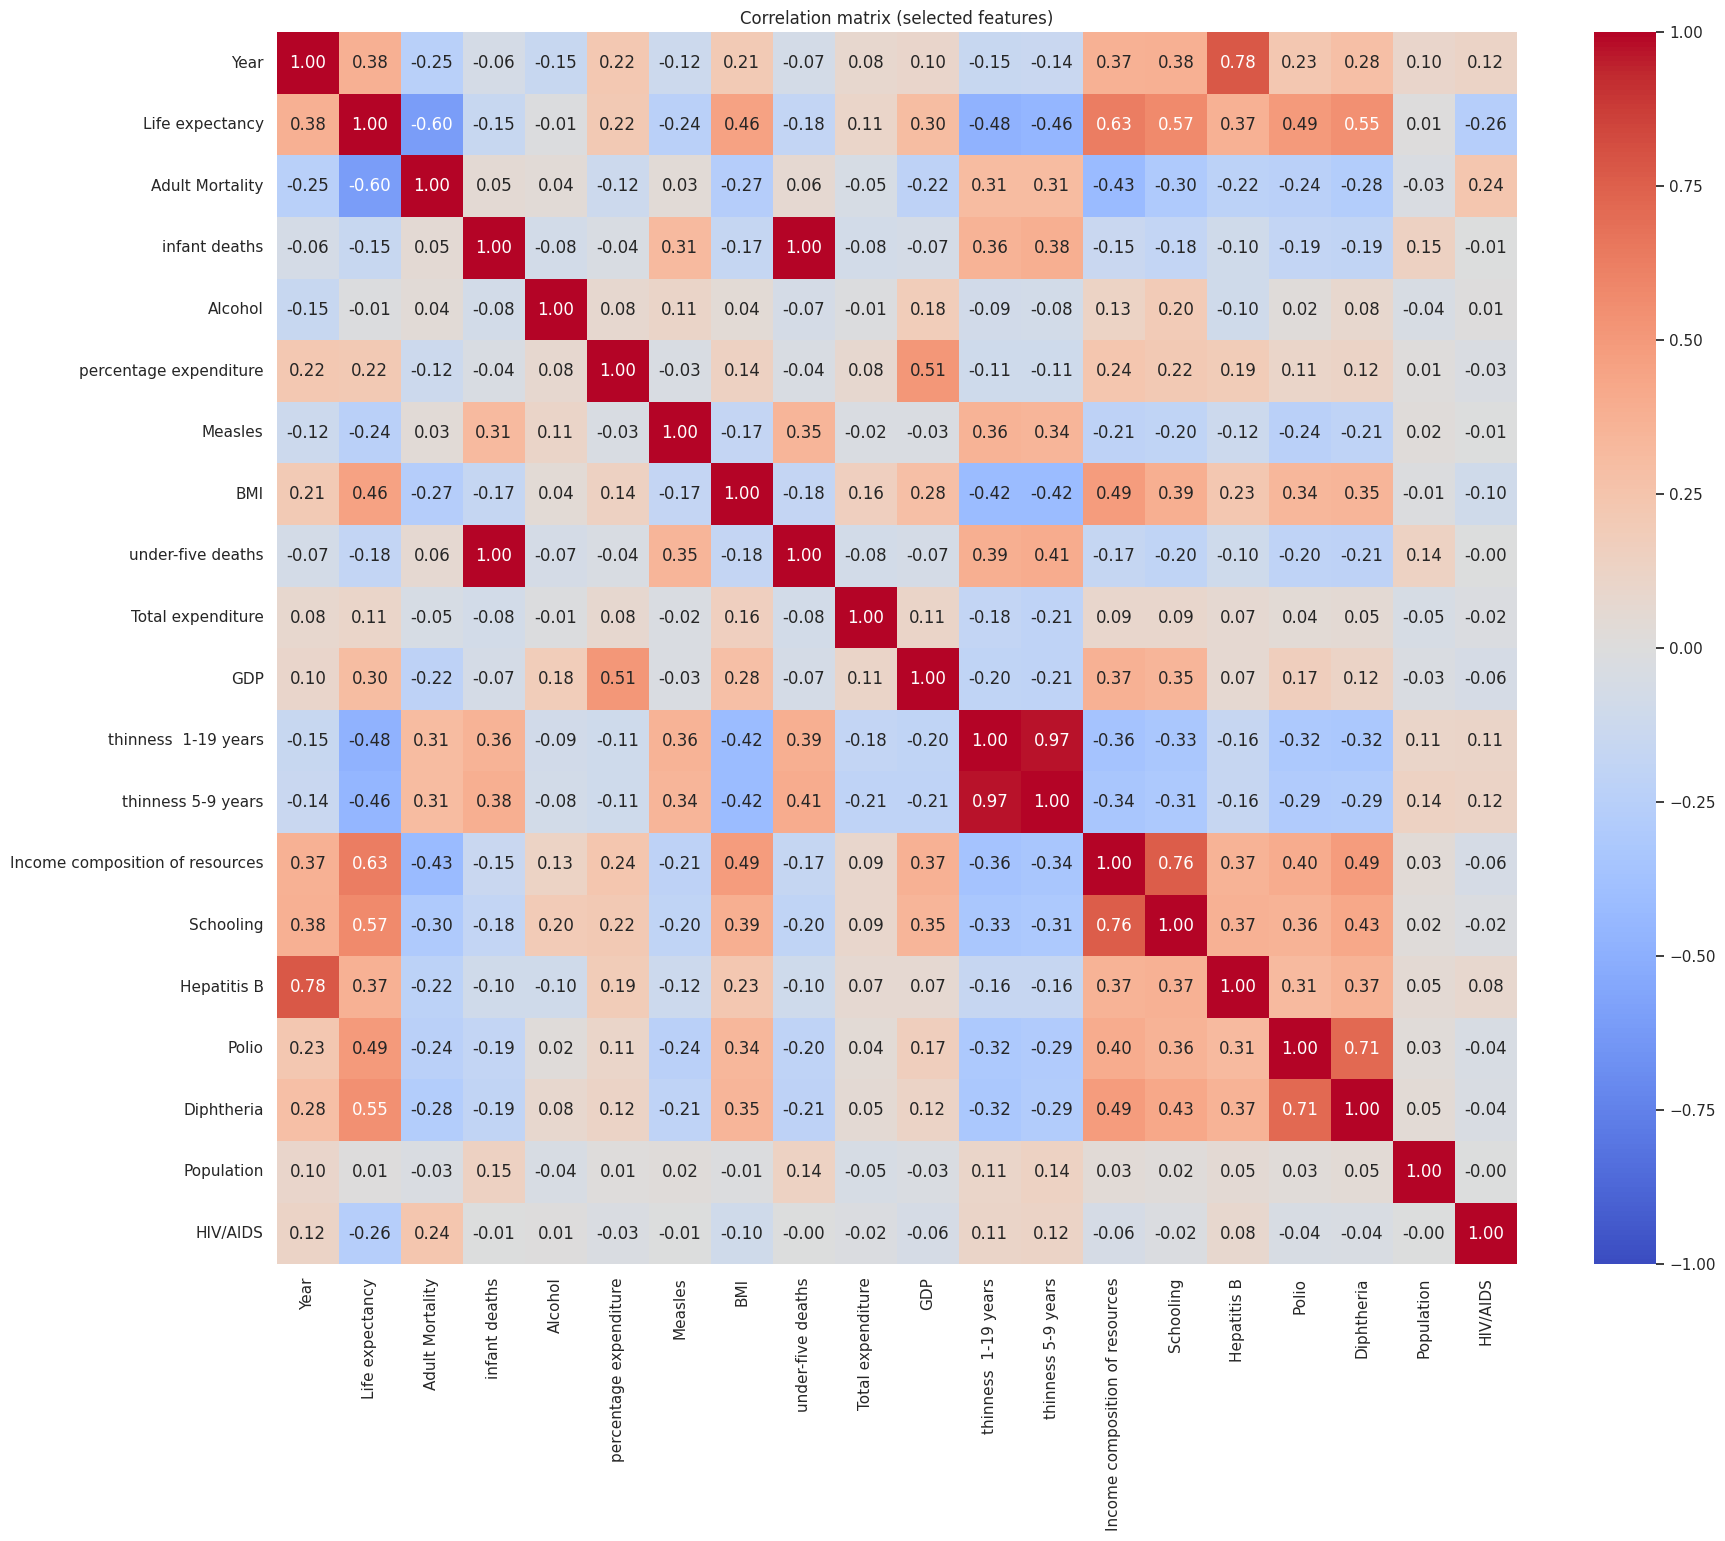

In [ ]:
# 4) Correlation heatmap for selected numeric features
# num_cols = ['Status', 'Life expectancy','Adult Mortality','infant deaths','under-five deaths','HIV/AIDS','GDP','Schooling', 'Total expenditure', 'percentage expenditure', 'Income composition of resources']
num_cols = df_eda.select_dtypes(include=[np.number]).columns.tolist()  # Automatically select numeric columns
corr_df = df_eda[num_cols].apply(pd.to_numeric, errors='coerce').corr()
plt.figure(figsize=(20, 16))
sns.heatmap(corr_df, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation matrix (selected features)')
plt.show()

- Pasangan kolom `infant deaths` dan `under-five deaths` serta pasangan kolom `thinness 5-9 years` dan `thinness 1-19 years` kofisien korelasinya dekat dengan satu, pertimbangkan untuk drop salah satu supaya tidak redundan. Akan tetapi, tetap ingat `correlation does not imply causation`
- Pasangan kolom `Schooling` dan `Income composition of resources` koefisien korelasinya lumayan besar (0.76), pertimbangkan untuk drop salah satu dari kedua kolom tersebut: Koefisien korelasi antara `Status` dengan `Schooling` lebih kecil dari pada dengan `Income composition of resources`, jadi, yang di-drop adalah kolom `Schooling` saja

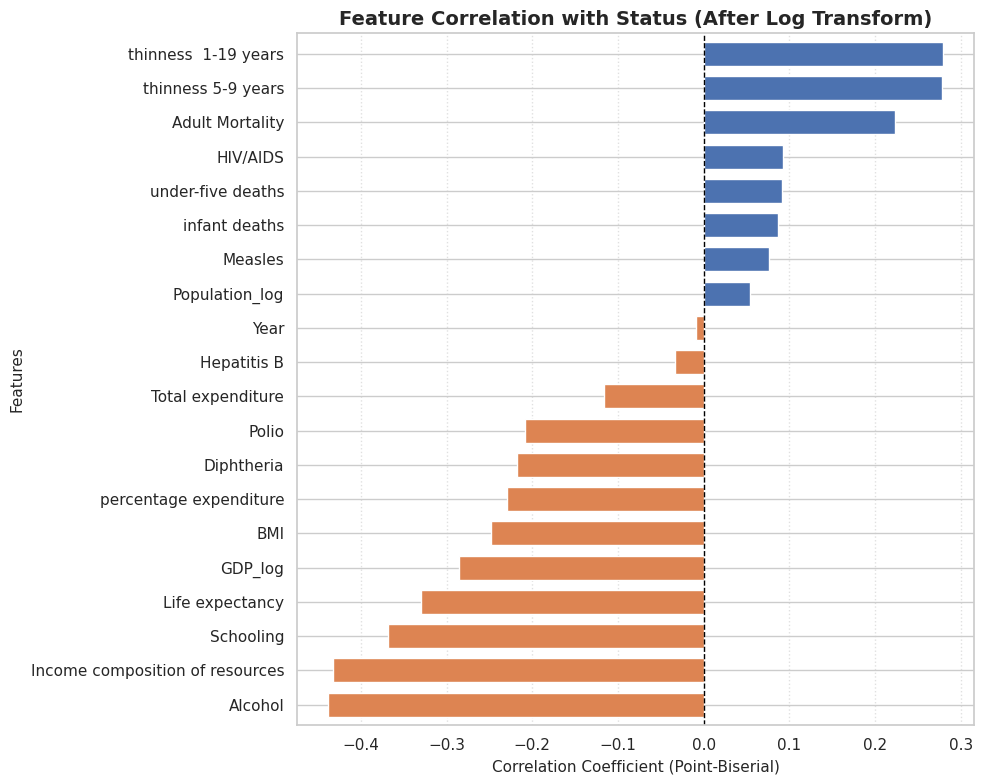

In [ ]:
if df_eda["Status"].dtype == "object":
    df_eda["Status"] = df_eda["Status"].str.strip()
    status_map = {"Developing": 1, "Developed": 0}
    df_eda["Status"] = df_eda["Status"].map(status_map)

df_eda["Status"] = pd.to_numeric(df_eda["Status"], errors="coerce")

# ==========================================
# LOG TRANSFORM UNTUK GDP & POPULATION
# ==========================================
df_eda["GDP_log"] = np.log1p(df_eda["GDP"])
df_eda["Population_log"] = np.log1p(df_eda["Population"])

# ==========================================
# HITUNG KORELASI ULANG
# ==========================================
num_cols = df_eda.select_dtypes(include=[np.number]).columns.tolist()

if "GDP" in num_cols:
    num_cols.remove("GDP")
if "Population" in num_cols:
    num_cols.remove("Population")

corr_with_target = (
    df_eda[num_cols].apply(pd.to_numeric, errors="coerce").corr()["Status"]
)

if "Status" in corr_with_target:
    corr_with_target = corr_with_target.drop("Status")

corr_with_target = corr_with_target.dropna().sort_values()

plt.figure(figsize=(10, 8))
colors = ["#DD8452" if v < 0 else "#4C72B0" for v in corr_with_target.values]

corr_with_target.plot(kind="barh", color=colors, edgecolor="white", width=0.7)
plt.axvline(0, color="black", linewidth=1, linestyle="--")

plt.title(
    "Feature Correlation with Status (After Log Transform)",
    fontsize=14,
    fontweight="bold",
)
plt.xlabel("Correlation Coefficient (Point-Biserial)", fontsize=11)
plt.ylabel("Features", fontsize=11)
plt.grid(axis="x", linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

Nampak korelasi fitur-fitur dengan target (Status). Korelasi positif berarti fitur sejalan dengan klasifikasi Developing pada suatu negara, sebaliknya korelasi negatif berarti fitur sejalan dengan klasifikasi Developed pada suatu negara.

### 2.7 Distribution of Target Variable

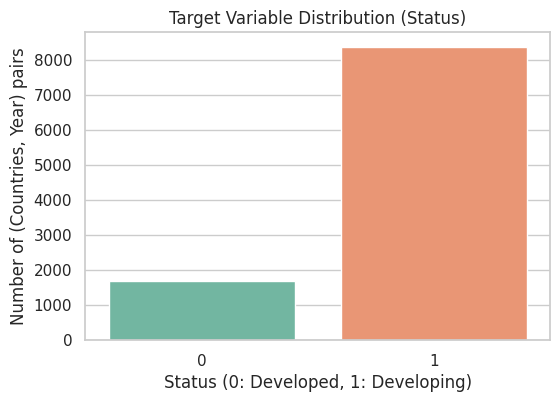

In [ ]:
# Ubah variabel target menjadi numerik (Developed = 0, Developing = 1)
# df_eda['Status'] = df_eda['Status'].map({'Developed': 0, 'Developing': 1})

plt.figure(figsize=(6, 4))
sns.countplot(x='Status', data=df_eda, palette='Set2')
plt.title('Target Variable Distribution (Status)')
plt.xlabel('Status (0: Developed, 1: Developing)')
plt.ylabel('Number of (Countries, Year) pairs')
plt.show()

## III. Data Preparation
### 3.0 Drop 'Life expectancy' and 'Status' (Target Variable)
Reason: Because it has a strong correlation with the target variable 'Status' and may lead to data leakage in predictive modeling. It is also because the column does not exist in the test dataset

In [ ]:
# Copy data untuk data preparation
df_prep = df_eda.copy()

# Simpan target variable (Status)
target = df_prep['Status']

# Drop 'Life expectancy' karena tidak ada di test.csv
df_prep = df_prep.drop(columns=['Life expectancy', 'Status'])

### 3.1 Drop Duplicate Rows

In [ ]:
# Cari baris duplikat
dup_bool = df_prep.duplicated(keep=False)
dup_rows = df_prep[dup_bool]

if dup_rows.empty:
    print("Tidak ada baris duplikat di df_prep.")
else:
    # Hitung frekuensi kemunculan setiap baris duplikat
    dup_counts = (
        dup_rows
        .groupby(list(df_prep.columns), dropna=False)
        .size()
        .reset_index(name='duplicate_count')
        .sort_values('duplicate_count', ascending=False)
    )
    print("Baris duplikat dan hitungan kemunculan (termasuk aslinya):")
    display(dup_counts)

    # Drop semua duplikat (tinggalkan satu baris per set duplikat)
    original_shape = df_prep.shape
    df_prep = df_prep.drop_duplicates(keep='first').reset_index(drop=True)
    new_shape = df_prep.shape

    print(f"\nShape awal: {original_shape}")
    print(f"Shape setelah drop duplicates: {new_shape}")
    print(f"Jumlah baris dihapus: {original_shape[0] - new_shape[0]}")

Tidak ada baris duplikat di df_prep.


### 3.2 Handling of Missing Values
For every columns in the dataset, count the percentage of its missing values. Then:
* If the percentage < 20%:
    * If the column is numerical, impute it with median value
    * Else if the column is categorical, impute it with its mode value
* Else, drop (or just do not use) the column

In [ ]:
# Identifikasi kolom numerik dan kategorikal
num_cols = df_prep.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = df_prep.select_dtypes(exclude=[np.number]).columns.tolist()

# Hapus 'Status' dari kolom kategorikal karena itu adalah target variable
if 'Status' in cat_cols:
    cat_cols.remove('Status')

print("Kolom Numerik:", num_cols)
print("Kolom Kategorikal:", cat_cols)

# Imputasi Missing Values untuk fitur numerik dengan MEDIAN
num_imputer = SimpleImputer(strategy='median')
df_prep[num_cols] = num_imputer.fit_transform(df_prep[num_cols])

# Imputasi Missing Values untuk fitur kategorikal dengan MODE (most frequent)
if cat_cols:
    cat_imputer = SimpleImputer(strategy='most_frequent')
    df_prep[cat_cols] = cat_imputer.fit_transform(df_prep[cat_cols])

# Verifikasi missing values
print("\nSisa Missing Values setelah imputasi:")
print(df_prep.isna().sum().sum())

Kolom Numerik: ['Year', 'Adult Mortality', 'infant deaths', 'Alcohol', 'percentage expenditure', 'Measles', 'BMI', 'under-five deaths', 'Total expenditure', 'GDP', 'thinness  1-19 years', 'thinness 5-9 years', 'Income composition of resources', 'Schooling', 'Hepatitis B', 'Polio', 'Diphtheria', 'Population', 'HIV/AIDS', 'GDP_log', 'Population_log']
Kolom Kategorikal: []

Sisa Missing Values setelah imputasi:
0


### 3.3 Feature Engineering
### 3.3.1 Principal Component Analysis (PCA)
Principal Component Analysis (PCA) adalah teknik dimensionality reduction yang mentransformasikan data bernilai real dengan dimensi tinggi ke dimensi yang lebih rendah sambil mempertahankan variansi maksimal. PCA mengidentifikasi vektor-vektor ortogonal (principal components) yang menangkap variansi terbesar dalam data.

Interpretasi:
- Explained Variance: proporsi variansi yang dijelaskan oleh setiap principal component
- Cumulative Variance: proporsi variansi kumulatif yang dijelaskan oleh k komponen pertama
- Threshold 90% variance sering digunakan sebagai standar retensi informasi

PCA IMPLEMENTATION MENGGUNAKAN SKLEARN

Total fitur (dimensi): 21
Jumlah komponen untuk 90% variance: 1
Reduksi dimensi: 21 → 1 (95.2% dimensi reduction)


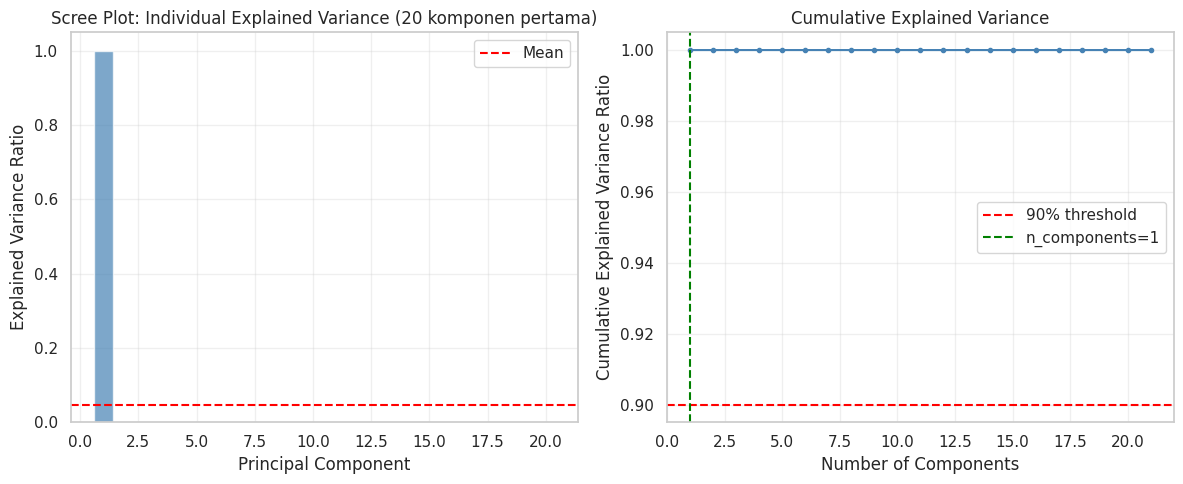


Variance Analysis (15 komponen pertama):


,PC,Explained Variance,Cumulative Variance,Variance %,Cumulative %
0,PC1,9.999985e-01,0.999998,100.0,100.0
1,PC2,1.362047e-06,1.000000,0.0,100.0
2,PC3,1.663103e-07,1.000000,0.0,100.0
3,PC4,8.603735e-10,1.000000,0.0,100.0
4,PC5,1.966671e-10,1.000000,0.0,100.0
5,PC6,5.079517e-11,1.000000,0.0,100.0
6,PC7,2.625166e-12,1.000000,0.0,100.0
7,PC8,1.435036e-12,1.000000,0.0,100.0
8,PC9,5.030782e-13,1.000000,0.0,100.0
9,PC10,4.026358e-13,1.000000,0.0,100.0



✓ PCA sklearn selesai


In [ ]:
print("=" * 70)
print("PCA IMPLEMENTATION MENGGUNAKAN SKLEARN")
print("=" * 70)

# Terapkan PCA dengan semua komponen
pca = PCA()
X_pca = pca.fit_transform(df_prep)

# Hitung explained variance ratio
explained_ratio = pca.explained_variance_ratio_
cum_var = np.cumsum(explained_ratio)

# Cari number of components untuk 90% variance
n_components_90 = np.argmax(cum_var >= 0.90) + 1

print(f"\nTotal fitur (dimensi): {df_prep.shape[1]}")
print(f"Jumlah komponen untuk 90% variance: {n_components_90}")
print(f"Reduksi dimensi: {df_prep.shape[1]} → {n_components_90} ({(1 - n_components_90/df_prep.shape[1])*100:.1f}% dimensi reduction)")

# Visualisasi: Scree Plot (Individual Explained Variance)
plt.figure(figsize=(12, 5))

# Subplot 1: Individual Explained Variance
plt.subplot(1, 2, 1)
plt.bar(range(1, min(21, len(explained_ratio) + 1)), explained_ratio[:20], alpha=0.7, color='steelblue')
plt.axhline(y=explained_ratio.mean(), color='r', linestyle='--', label='Mean')
plt.title('Scree Plot: Individual Explained Variance (20 komponen pertama)')
plt.xlabel('Principal Component')
plt.ylabel('Explained Variance Ratio')
plt.legend()
plt.grid(alpha=0.3)

# Subplot 2: Cumulative Explained Variance
plt.subplot(1, 2, 2)
plt.plot(range(1, len(cum_var) + 1), cum_var, marker='o', linestyle='-', color='steelblue', markersize=3)
plt.axhline(y=0.90, color='r', linestyle='--', label='90% threshold')
plt.axvline(x=n_components_90, color='g', linestyle='--', label=f'n_components={n_components_90}')
plt.title('Cumulative Explained Variance')
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance Ratio')
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Tabel: Variance Analysis untuk 15 komponen pertama
variance_table = pd.DataFrame({
    'PC': [f'PC{i+1}' for i in range(min(15, len(explained_ratio)))],
    'Explained Variance': explained_ratio[:min(15, len(explained_ratio))],
    'Cumulative Variance': cum_var[:min(15, len(explained_ratio))],
    'Variance %': (explained_ratio[:min(15, len(explained_ratio))] * 100).round(2),
    'Cumulative %': (cum_var[:min(15, len(explained_ratio))] * 100).round(2)
})

print("\nVariance Analysis (15 komponen pertama):")
display(variance_table)

print(f"\n✓ PCA sklearn selesai")

### 3.3.2 Analisis Perbandingan: Sebelum vs Sesudah PCA
Bagian ini membandingkan karakteristik data:
- **Sebelum PCA**: Data dalam ruang fitur asli yang sudah distandardisasi (20 dimensi)
- **Sesudah PCA**: Data dalam ruang principal components (ke-n dimensi yang dipilih)
- **Kualitas Rekonstruksi**: Seberapa baik data dapat direkonstruksi dari komponen yang dipilih

**Tujuan:** Memahami trade-off antara dimensi reduction dan retensi informasi, serta dampak PCA terhadap struktur data.

In [ ]:
# print("=" * 70)
# print("ANALISIS PERBANDINGAN: SEBELUM vs SESUDAH PCA")
# print("=" * 70)

# # ============================================================================
# # 1. VISUALISASI 2D: Sebelum vs Sesudah PCA
# # ============================================================================
# print("\n1. Visualisasi 2D Projection (PC1 vs PC2):")

# pca_2d = PCA(n_components=2)
# X_pca_2d = pca_2d.fit_transform(df_prep)

# fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# # Sebelum PCA: gunakan 2 fitur asli pertama
# scatter1 = axes[0].scatter(df_prep[:, 0], df_prep[:, 1], c=target, cmap='viridis', alpha=0.6, s=30)
# axes[0].set_xlabel(f'{X_prepared.columns[0]} (scaled)')
# axes[0].set_ylabel(f'{X_prepared.columns[1]} (scaled)')
# axes[0].set_title('Sebelum PCA\n(2 Fitur Asli Pertama)')
# axes[0].grid(alpha=0.3)

# # Sesudah PCA: PC1 dan PC2
# scatter2 = axes[1].scatter(X_pca_2d[:, 0], X_pca_2d[:, 1], c=y_prepared, cmap='viridis', alpha=0.6, s=30)
# axes[1].set_xlabel(f'PC1 (Explained Var: {pca_2d.explained_variance_ratio_[0]*100:.2f}%)')
# axes[1].set_ylabel(f'PC2 (Explained Var: {pca_2d.explained_variance_ratio_[1]*100:.2f}%)')
# axes[1].set_title('Sesudah PCA\n(PC1 vs PC2)')
# axes[1].grid(alpha=0.3)

# # Colorbar
# fig.colorbar(scatter2, ax=axes, label='Status (0: Developing, 1: Developed)', orientation='horizontal', pad=0.1)
# plt.tight_layout()
# plt.show()

# print(f"✓ PC1 + PC2 menangkap {(pca_2d.explained_variance_ratio_.sum() * 100):.2f}% variansi")

In [ ]:
# # ============================================================================
# # 2. VISUALISASI 3D: Sebelum vs Sesudah PCA
# # ============================================================================
# print("\n2. Visualisasi 3D Projection (PC1 vs PC2 vs PC3):")

# pca_3d = PCA(n_components=3)
# X_pca_3d = pca_3d.fit_transform(df_prep)

# from mpl_toolkits.mplot3d import Axes3D

# fig = plt.figure(figsize=(16, 6))

# # Sebelum PCA: 3 fitur asli pertama
# ax1 = fig.add_subplot(121, projection='3d')
# scatter1_3d = ax1.scatter(df_prep[:, 0], df_prep[:, 1], df_prep[:, 2], c=y_prepared, cmap='viridis', alpha=0.6, s=20)
# ax1.set_xlabel(f'{X_prepared.columns[0]}')
# ax1.set_ylabel(f'{X_prepared.columns[1]}')
# ax1.set_zlabel(f'{X_prepared.columns[2]}')
# ax1.set_title('Sebelum PCA (3 Fitur Asli Pertama)')

# # Sesudah PCA: 3 komponen pertama
# ax2 = fig.add_subplot(122, projection='3d')
# scatter2_3d = ax2.scatter(X_pca_3d[:, 0], X_pca_3d[:, 1], X_pca_3d[:, 2], c=y_prepared, cmap='viridis', alpha=0.6, s=20)
# ax2.set_xlabel(f'PC1 ({pca_3d.explained_variance_ratio_[0]*100:.1f}%)')
# ax2.set_ylabel(f'PC2 ({pca_3d.explained_variance_ratio_[1]*100:.1f}%)')
# ax2.set_zlabel(f'PC3 ({pca_3d.explained_variance_ratio_[2]*100:.1f}%)')
# ax2.set_title('Sesudah PCA (PC1 vs PC2 vs PC3)')

# plt.colorbar(scatter2_3d, ax=ax2, pad=0.1, label='Status', shrink=0.8)
# plt.tight_layout()
# plt.show()

# print(f"✓ PC1 + PC2 + PC3 menangkap {(pca_3d.explained_variance_ratio_.sum() * 100):.2f}% variansi")

In [ ]:
# # ============================================================================
# # 3. ANALISIS REKONSTRUKSI DATA
# # ============================================================================
# print("\n3. Analisis Kualitas Rekonstruksi:")

def calculate_reconstruction_error(X_original, pca_model, n_components):
    """Hitung MSE rekonstruksi setelah dimensionality reduction"""
    X_reduced = pca_model.transform(X_original)[:, :n_components]
    # Proyeksikan kembali ke ruang asli
    X_reconstructed = pca_model.inverse_transform(np.hstack([X_reduced, np.zeros((X_reduced.shape[0], pca_model.n_components_ - n_components))]))
    mse = np.mean((X_original - X_reconstructed) ** 2)
    return mse, X_reconstructed

# # Hitung reconstruction error untuk berbagai jumlah komponen
# n_components_range = [2, 3, 5, 10, n_components_90, len(explained_ratio)]
# reconstruction_errors = []

pca_full = PCA()
pca_full.fit(df_prep)

# for n_comp in n_components_range:
#     if n_comp <= len(explained_ratio):
#         mse, _ = calculate_reconstruction_error(df_prep, pca_full, n_comp)
#         reconstruction_errors.append({'n_components': n_comp, 'MSE': mse, 'RMSE': np.sqrt(mse)})

# recon_df = pd.DataFrame(reconstruction_errors)
# print("\nReconstruction Error untuk berbagai jumlah komponen:")
# display(recon_df)

# # Visualisasi Reconstruction Error
# fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# # Plot 1: MSE vs n_components
# axes[0].plot(recon_df['n_components'], recon_df['MSE'], marker='o', linewidth=2, markersize=8, color='steelblue')
# axes[0].axvline(x=n_components_90, color='r', linestyle='--', label=f'n_components={n_components_90} (90% var)')
# axes[0].set_xlabel('Number of Components')
# axes[0].set_ylabel('Mean Squared Error (MSE)')
# axes[0].set_title('Reconstruction Error vs Number of Components')
# axes[0].set_yscale('log')
# axes[0].legend()
# axes[0].grid(alpha=0.3)

# # Plot 2: RMSE vs n_components
# axes[1].plot(recon_df['n_components'], recon_df['RMSE'], marker='s', linewidth=2, markersize=8, color='coral')
# axes[1].axvline(x=n_components_90, color='r', linestyle='--', label=f'n_components={n_components_90} (90% var)')
# axes[1].set_xlabel('Number of Components')
# axes[1].set_ylabel('Root Mean Squared Error (RMSE)')
# axes[1].set_title('Reconstruction RMSE vs Number of Components')
# axes[1].legend()
# axes[1].grid(alpha=0.3)

# plt.tight_layout()
# plt.show()

PCA()

In [ ]:
# # ============================================================================
# # 4. SCATTER PLOT: ORIGINAL VS RECONSTRUCTED (Fitur Pertama)
# # ============================================================================
# print("\n4. Visualisasi Korelasi: Sebelum vs Sesudah Rekonstruksi:")

mse_90, X_reconstructed_90 = calculate_reconstruction_error(df_prep, pca_full, n_components_90)

# fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# # Fitur pertama
# axes[0].scatter(df_prep[:, 0], X_reconstructed_90[:, 0], alpha=0.5, s=20)
# axes[0].plot([-3, 3], [-3, 3], 'r--', label='Perfect reconstruction', linewidth=2)
# axes[0].set_xlabel('Original Feature (scaled)')
# axes[0].set_ylabel('Reconstructed Feature')
# axes[0].set_title(f'Feature 1: {X_prepared.columns[0]}\nReconstruction via {n_components_90} PCs (MSE={mse_90:.4f})')
# axes[0].legend()
# axes[0].grid(alpha=0.3)

# # Fitur kedua
# mse_2, X_reconstructed_2 = calculate_reconstruction_error(df_prep, pca_full, 2)
# axes[1].scatter(df_prep[:, 1], X_reconstructed_2[:, 1], alpha=0.5, s=20, color='orange')
# axes[1].plot([-3, 3], [-3, 3], 'r--', label='Perfect reconstruction', linewidth=2)
# axes[1].set_xlabel('Original Feature (scaled)')
# axes[1].set_ylabel('Reconstructed Feature')
# axes[1].set_title(f'Feature 2: {X_prepared.columns[1]}\nReconstruction via 2 PCs (MSE={mse_2:.4f})')
# axes[1].legend()
# axes[1].grid(alpha=0.3)

# plt.tight_layout()
# plt.show()

# print(f"\n✓ Reconstruction analysis selesai")



5. PCA Loadings Analysis (Fitur yang paling mempengaruhi Principal Components):

PCA Loadings (5 komponen pertama):


,PC1,PC2,PC3,PC4,PC5
Year,5.363258e-08,-0.000068,0.000124,4.579823e-03,-0.002013
Adult Mortality,-1.585738e-07,0.000205,-0.003807,-4.076523e-03,0.030637
infant deaths,1.296159e-06,0.002325,-0.001099,7.101910e-04,0.581764
Alcohol,-8.456555e-09,0.000020,0.000094,-1.212702e-04,-0.001478
percentage expenditure,2.512092e-07,-0.001076,0.043124,9.990364e-01,-0.001151
Measles,2.257163e-05,0.999940,0.010041,6.394861e-04,-0.004309
BMI,-9.527720e-09,-0.000120,0.000532,2.217663e-05,-0.006489
under-five deaths,1.716673e-06,0.003646,-0.001613,1.278961e-03,0.812505
Total expenditure,-7.617376e-09,-0.000003,0.000037,1.355348e-04,-0.000660
GDP,-1.143136e-05,-0.009994,0.999010,-4.314648e-02,0.002177


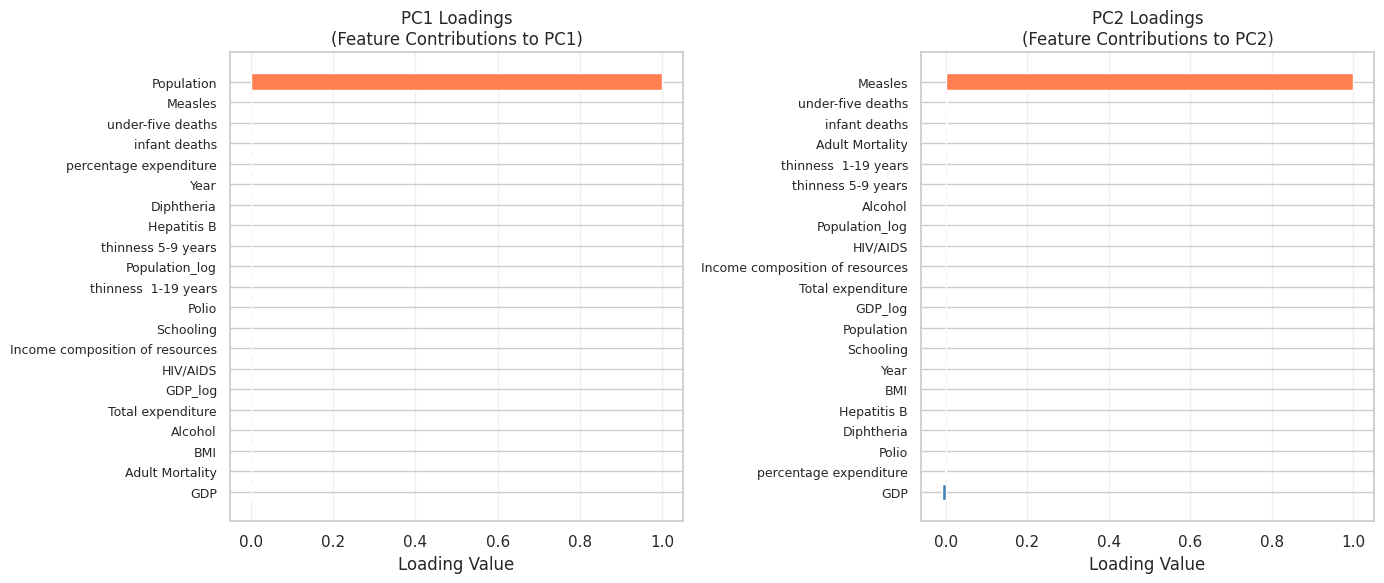


✓ PCA analysis selesai!

RINGKASAN PCA
Original dimensionality: 21
Dimensionality after PCA (90% var retention): 1
Dimensionality reduction: 21 → 1 (95.2% reduction)
Reconstruction MSE (1 components): 62643541.010568

Top 5 features yang paling berkontribusi pada PC1:
Population           1.000000
Measles              0.000023
GDP                  0.000011
under-five deaths    0.000002
infant deaths        0.000001
Name: PC1, dtype: float64


In [ ]:
# ============================================================================
# 5. PCA LOADINGS: Fitur yang Paling Berpengaruh pada PC1 & PC2
# ============================================================================
print("\n5. PCA Loadings Analysis (Fitur yang paling mempengaruhi Principal Components):")

pca_loadings = PCA(n_components=5)
pca_loadings.fit(df_prep)

# Buat DataFrame untuk loadings
loadings_df = pd.DataFrame(
    pca_loadings.components_.T,
    columns=[f'PC{i+1}' for i in range(pca_loadings.n_components_)],
    index=df_prep.columns
)

print("\nPCA Loadings (5 komponen pertama):")
display(loadings_df)

# Visualisasi Loadings untuk PC1 dan PC2
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# PC1 Loadings
pc1_loadings = loadings_df['PC1'].sort_values()
colors_pc1 = ['steelblue' if x < 0 else 'coral' for x in pc1_loadings.values]
axes[0].barh(range(len(pc1_loadings)), pc1_loadings.values, color=colors_pc1)
axes[0].set_yticks(range(len(pc1_loadings)))
axes[0].set_yticklabels(pc1_loadings.index, fontsize=9)
axes[0].set_xlabel('Loading Value')
axes[0].set_title('PC1 Loadings\n(Feature Contributions to PC1)')
axes[0].grid(alpha=0.3, axis='x')

# PC2 Loadings
pc2_loadings = loadings_df['PC2'].sort_values()
colors_pc2 = ['steelblue' if x < 0 else 'coral' for x in pc2_loadings.values]
axes[1].barh(range(len(pc2_loadings)), pc2_loadings.values, color=colors_pc2)
axes[1].set_yticks(range(len(pc2_loadings)))
axes[1].set_yticklabels(pc2_loadings.index, fontsize=9)
axes[1].set_xlabel('Loading Value')
axes[1].set_title('PC2 Loadings\n(Feature Contributions to PC2)')
axes[1].grid(alpha=0.3, axis='x')

plt.tight_layout()
plt.show()

print(f"\n✓ PCA analysis selesai!")
print("\n" + "=" * 70)
print("RINGKASAN PCA")
print("=" * 70)
print(f"Original dimensionality: {df_prep.shape[1]}")
print(f"Dimensionality after PCA (90% var retention): {n_components_90}")
print(f"Dimensionality reduction: {df_prep.shape[1]} → {n_components_90} ({(1-n_components_90/df_prep.shape[1])*100:.1f}% reduction)")
print(f"Reconstruction MSE ({n_components_90} components): {mse_90:.6f}")
print(f"\nTop 5 features yang paling berkontribusi pada PC1:")
print(loadings_df['PC1'].abs().sort_values(ascending=False).head())

### 3.3.4 Creating Features

,infant deaths,under-five deaths,Total Under-Five Deaths,Hepatitis B,Polio,Diphtheria,Immunization Average,Schooling,Income composition of resources,schooling_x_income
0,7.0,10.0,17.0,0.0,76.0,92.0,56.000000,12.774990,0.747018,9.543146
1,18.0,28.0,46.0,100.0,53.0,35.0,62.666667,9.982904,0.300171,2.996580
2,81.0,108.0,189.0,0.0,100.0,100.0,66.666667,7.317002,0.440699,3.224599
3,168.0,298.0,466.0,0.0,83.0,63.0,48.666667,12.300000,0.677000,8.327100
4,162.0,243.0,405.0,62.0,69.0,61.0,64.000000,8.100000,0.401000,3.248100


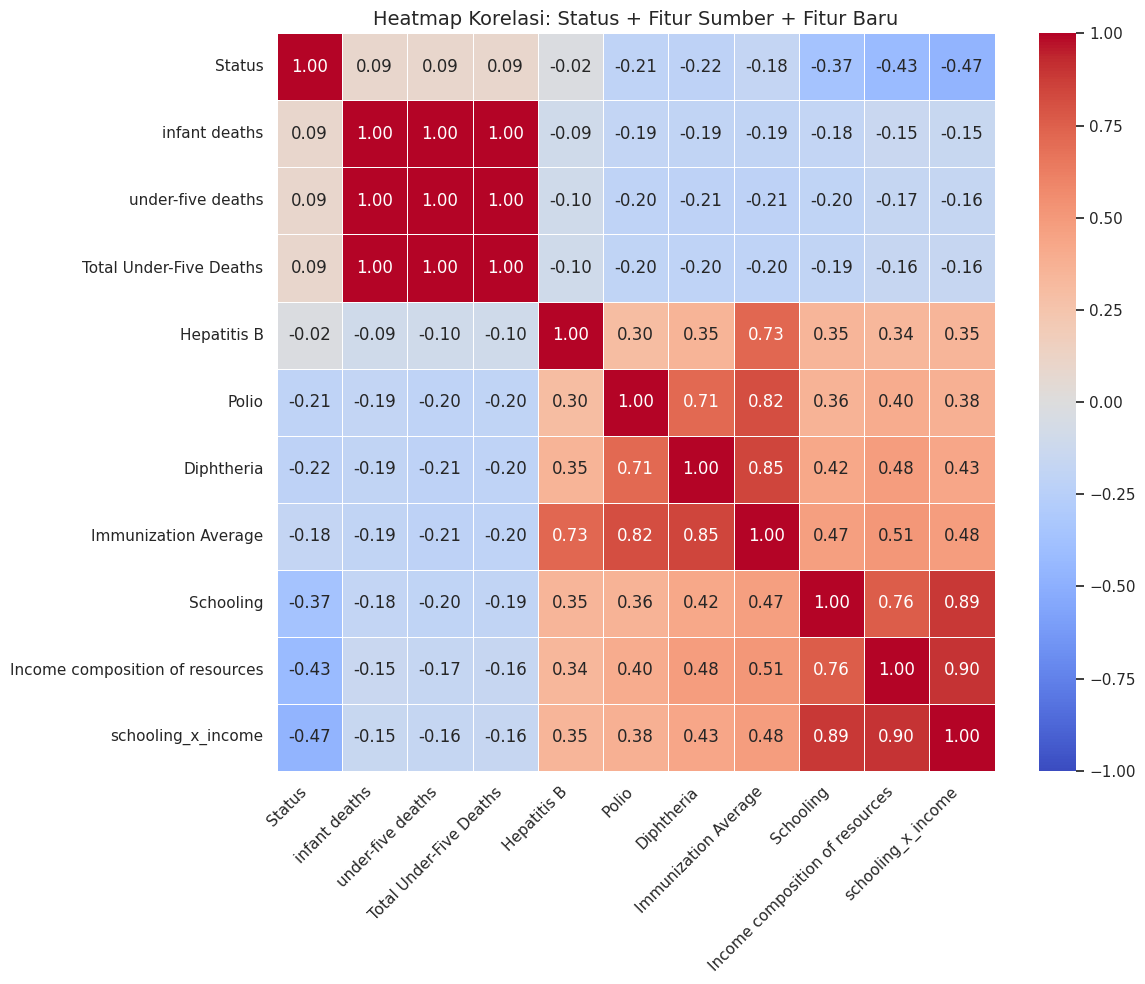

In [ ]:
# Feature Engineering pada df_prep
df_prep['Total Under-Five Deaths'] = df_prep['infant deaths'] + df_prep['under-five deaths']
df_prep['Immunization Average'] = df_prep[['Hepatitis B', 'Polio', 'Diphtheria']].mean(axis=1)
df_prep['Thinness Average'] = (df_prep['thinness  1-19 years'] + df_prep['thinness 5-9 years']) / 2
df_prep['schooling_x_income'] = df_prep['Schooling'] * df_prep['Income composition of resources']

# Jika ingin melihat hasilnya
display(df_prep[['infant deaths', 'under-five deaths', 'Total Under-Five Deaths',
                 'Hepatitis B', 'Polio', 'Diphtheria', 'Immunization Average',
                 'Schooling', 'Income composition of resources', 'schooling_x_income']].head())

# Pastikan kolom target tersedia untuk korelasi
df_corr = df_prep.copy()
df_corr['Status'] = target.reset_index(drop=True)

# Kolom yang relevan untuk heatmap
cols_heatmap = [
    'Status',
    'infant deaths', 'under-five deaths', 'Total Under-Five Deaths',
                 'Hepatitis B', 'Polio', 'Diphtheria', 'Immunization Average',
                 'Schooling', 'Income composition of resources', 'schooling_x_income'
]

corr_mat = df_corr[cols_heatmap].corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr_mat, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Heatmap Korelasi: Status + Fitur Sumber + Fitur Baru', fontsize=14)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### 3.4 Outliers Handling

OUTLIERS HANDLING - IQR Method dengan Capping

Outliers Detection Summary:
                             column   lower_bound   upper_bound  \
0                              Year  1.918000e+03  2.046000e+03   
1                   Adult Mortality -2.161929e+02  6.088863e+02   
2                     infant deaths -4.350000e+01  7.250000e+01   
3                           Alcohol -1.118986e+01  2.051192e+01   
4            percentage expenditure -1.500000e+02  2.500000e+02   
5                           Measles -3.720000e+03  6.200000e+03   
6                               BMI -5.776915e+01  1.144103e+02   
7                 under-five deaths -6.150000e+01  1.025000e+02   
8                 Total expenditure -4.436037e+00  1.392982e+01   
9                               GDP -2.625421e+03  4.402369e+03   
10             thinness  1-19 years -7.454443e+00  1.669210e+01   
11               thinness 5-9 years -7.950000e+00  1.725000e+01   
12  Income composition of resources -2.665956e-01  1.2

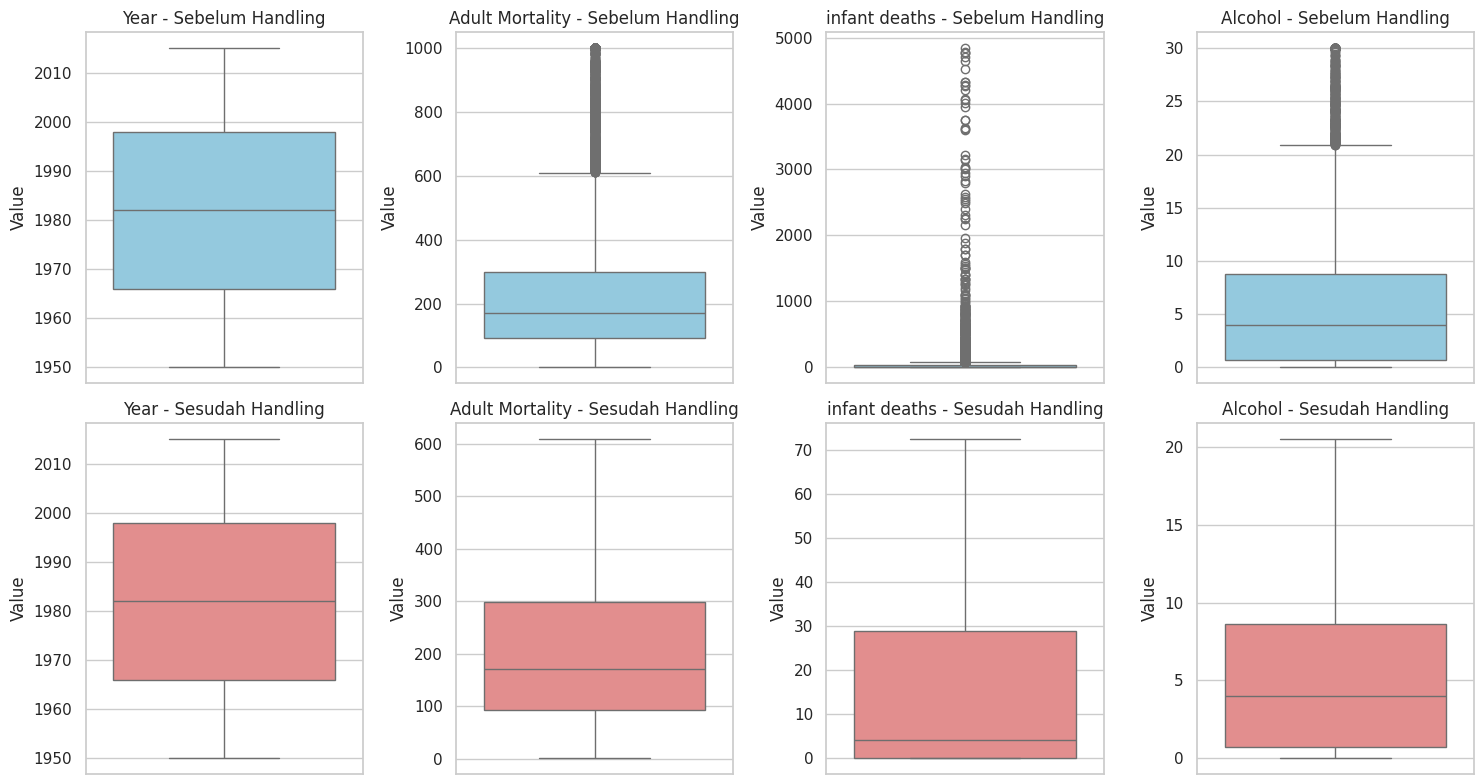


✓ Outliers Handling selesai dengan Capping


In [ ]:
# Penanganan Outliers menggunakan IQR Method dengan Capping
print("=" * 60)
print("OUTLIERS HANDLING - IQR Method dengan Capping")
print("=" * 60)

def handle_outliers_iqr_capping(dataframe, column):
    """
    Mendeteksi dan menangani outliers menggunakan IQR method dengan capping.
    Outliers dibatasi ke batas atas/bawah IQR (1.5 * IQR) alih-alih dihapus.
    """
    Q1 = dataframe[column].quantile(0.25)
    Q3 = dataframe[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Hitung jumlah outliers
    outliers = dataframe[(dataframe[column] < lower_bound) | (dataframe[column] > upper_bound)]
    outlier_count = len(outliers)
    outlier_pct = (outlier_count / len(dataframe)) * 100

    # Terapkan capping (winsorization)
    dataframe_capped = dataframe.copy()
    dataframe_capped[column] = np.where(dataframe_capped[column] < lower_bound, lower_bound, dataframe_capped[column])
    dataframe_capped[column] = np.where(dataframe_capped[column] > upper_bound, upper_bound, dataframe_capped[column])

    return {
        'column': column,
        'Q1': Q1,
        'Q3': Q3,
        'IQR': IQR,
        'lower_bound': lower_bound,
        'upper_bound': upper_bound,
        'outlier_count': outlier_count,
        'outlier_pct': outlier_pct
    }, dataframe_capped

# Terapkan outlier handling pada semua fitur numerik (kecuali Status)
outlier_summary = []
df_prep_capped = df_prep.copy()

for col in num_cols:
    if col != 'Status':
        outlier_info, df_prep_temp = handle_outliers_iqr_capping(df_prep_capped, col)
        df_prep_capped = df_prep_temp.copy()
        outlier_summary.append(outlier_info)

outlier_df = pd.DataFrame(outlier_summary)
print("\nOutliers Detection Summary:")
print(outlier_df[['column', 'lower_bound', 'upper_bound', 'outlier_count', 'outlier_pct']])

# Update df_prep dengan data yang sudah di-cap
df_prep = df_prep_capped.copy()

# Visualisasi: Boxplot Sebelum dan Sesudah Handling Outliers
sample_cols = num_cols[:min(4, len(num_cols))]  # Pilih 4 kolom pertama untuk visualisasi
if sample_cols:
    fig, axes = plt.subplots(2, len(sample_cols), figsize=(15, 8))

    for idx, col in enumerate(sample_cols):
        # Sebelum (gunakan data dari EDA sebelumnya)
        sns.boxplot(y=df_eda[col], ax=axes[0, idx], color='skyblue')
        axes[0, idx].set_title(f'{col} - Sebelum Handling')
        axes[0, idx].set_ylabel('Value')

        # Sesudah
        sns.boxplot(y=df_prep[col], ax=axes[1, idx], color='lightcoral')
        axes[1, idx].set_title(f'{col} - Sesudah Handling')
        axes[1, idx].set_ylabel('Value')

    plt.tight_layout()
    plt.show()

print("\n✓ Outliers Handling selesai dengan Capping")

### 3.5 Encoding of Categorical Columns
"Cardinality" means the number of unique values in a column. Select categorical columns with relatively low (< 10) cardinality (convenient but arbitrary)

In [ ]:
from sklearn.preprocessing import LabelEncoder

print("=" * 60)
print("ENCODING CATEGORICAL COLUMNS")
print("=" * 60)

# Identifikasi kolom kategorikal
categorical_features = df_prep.select_dtypes(include=['object']).columns.tolist()
print(f"Kolom Kategorikal: {categorical_features}")

if categorical_features:
    # Terapkan Label Encoding untuk fitur kategorikal
    df_prep_encoded = df_prep.copy()
    label_encoders = {}

    for col in categorical_features:
        le = LabelEncoder()
        df_prep_encoded[col] = le.fit_transform(df_prep[col])
        label_encoders[col] = le

        print(f"\n{col}:")
        for idx, class_name in enumerate(le.classes_):
            print(f"  {class_name} → {le.transform([class_name])[0]}")

    # Update df_prep
    df_prep = df_prep_encoded.copy()
    print("\n✓ Label Encoding selesai")
else:
    print("Tidak ada kolom kategorikal yang perlu di-encode.")

ENCODING CATEGORICAL COLUMNS
Kolom Kategorikal: []
Tidak ada kolom kategorikal yang perlu di-encode.


## IV. Model
### 4.1 Train the CatBoost Model

In [ ]:
pip install catboost

In [ ]:
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score, StratifiedKFold
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from catboost import CatBoostClassifier

print("=" * 70)

print("MODEL TRAINING AND EVALUATION")

print("=" * 70)

# Gunakan data yang sudah di-scaled (X_scaled) dan target (y_prepared)
X_train = df_prep
y_train = target

# Split data untuk validation
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42, stratify=y_train)

print(f"Training set size: {X_tr.shape[0]}")
print(f"Validation set size: {X_val.shape[0]}")
print(f"Class distribution in training: {np.bincount(y_tr)}")
print(f"Class distribution in validation: {np.bincount(y_val)}")

MODEL TRAINING AND EVALUATION
Training set size: 8056
Validation set size: 2014
Class distribution in training: [1352 6704]
Class distribution in validation: [ 338 1676]


In [ ]:
# CatBoost Model using Hyperparameter Tuning
print("=" * 70)
print("Training CatBoost with Hyperparameter Tuning")
print("=" * 70)

cb_model = CatBoostClassifier(
    random_state=42,
    verbose=0,
    thread_count=-1
)

param_grid_cb = {
    'iterations': [i*50 for i in range(1, 8)],
    'depth': [3, 5, 7, 9],
    'learning_rate': [0.01, 0.05, 0.1],
    'subsample': [0.7, 0.8, 0.9],
    'colsample_bylevel': [0.7, 0.8, 0.9]
}

# Reduced grid for faster training
param_grid_cb_reduced = {
    'iterations': [100, 200, 300],
    'depth': [5, 7],
    'learning_rate': [0.05, 0.1],
    'subsample': [0.7, 1.0],
    'colsample_bylevel': [0.7, 1.0]
}

print("Running GridSearchCV for CatBoost...")
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
grid_search_cb = GridSearchCV(
    cb_model,
    param_grid_cb_reduced,
    cv=cv,
    scoring='f1',
    n_jobs=-1,
    verbose=1
)

grid_search_cb.fit(X_tr, y_tr)

print(f"Best CatBoost parameters: {grid_search_cb.best_params_}")
print(f"Best CatBoost CV score: {grid_search_cb.best_score_:.4f}")

# Evaluate on validation set
y_pred_cb = grid_search_cb.predict(X_val)
cb_accuracy = accuracy_score(y_val, y_pred_cb)
print(f"CatBoost Validation Accuracy: {cb_accuracy:.4f}")
cb_f1 = f1_score(y_val, y_pred_cb)
print(f"CatBoost Validation F1-Score: {cb_f1:.4f}")

Training CatBoost with Hyperparameter Tuning
Running GridSearchCV for CatBoost...
Fitting 5 folds for each of 48 candidates, totalling 240 fits
Best CatBoost parameters: {'colsample_bylevel': 0.7, 'depth': 7, 'iterations': 300, 'learning_rate': 0.05, 'subsample': 0.7}
Best CatBoost CV score: 0.9984
CatBoost Validation Accuracy: 0.9980
CatBoost Validation F1-Score: 0.9988


MODEL Informations
Best Model: CatBoost with accuracy 0.9980
Best Model: CatBoost with F1-Score 0.9988
Classification Report (Best Model):
              precision    recall  f1-score   support

   Developed       1.00      0.99      0.99       338
  Developing       1.00      1.00      1.00      1676

    accuracy                           1.00      2014
   macro avg       1.00      0.99      1.00      2014
weighted avg       1.00      1.00      1.00      2014

Confusion Matrix:
[[ 334    4]
 [   0 1676]]


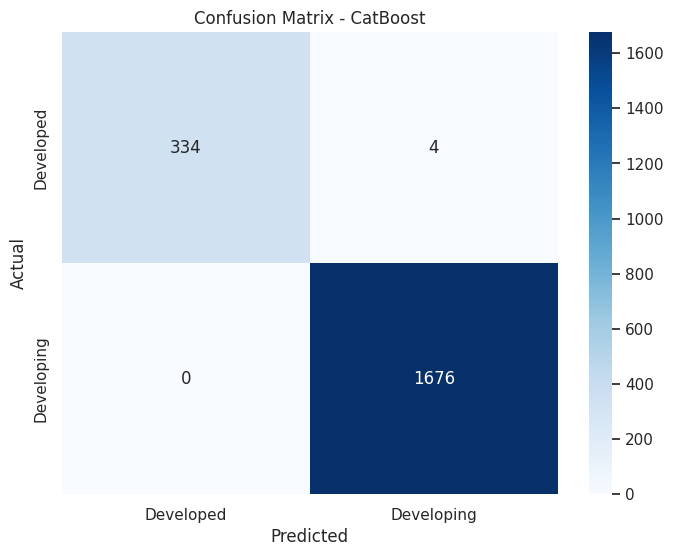

In [ ]:
print("=" * 70)
print("MODEL Informations")
print("=" * 70)

best_model = grid_search_cb.best_estimator_
best_model_name = "CatBoost"
best_accuracy = cb_accuracy
best_f1 = cb_f1

print(f"Best Model: {best_model_name} with accuracy {best_accuracy:.4f}")
print(f"Best Model: {best_model_name} with F1-Score {best_f1:.4f}")

# Classification Report untuk best model
y_pred_best = best_model.predict(X_val)
print(f"Classification Report (Best Model):")
print(classification_report(y_val, y_pred_best, target_names=['Developed', 'Developing']))

# Confusion Matrix
print("Confusion Matrix:")
cm = confusion_matrix(y_val, y_pred_best)
print(cm)

# Visualisasi Confusion Matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Developed', 'Developing'], yticklabels=['Developed', 'Developing'])
plt.title(f"Confusion Matrix - {best_model_name}")
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [ ]:
importances = best_model.get_feature_importance()
feature_names = X_train.columns
features_importance = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
print(features_importance)

                            Feature  Importance
0                              Year    2.378699
1                   Adult Mortality    4.963542
2                     infant deaths    4.209818
3                           Alcohol   14.232523
4            percentage expenditure    1.657586
5                           Measles    7.195441
6                               BMI    5.611110
7                 under-five deaths    4.759020
8                 Total expenditure    3.873279
9                               GDP    2.274527
10             thinness  1-19 years    4.621057
11               thinness 5-9 years    5.645072
12  Income composition of resources    6.955297
13                        Schooling    1.209069
14                      Hepatitis B    1.136234
15                            Polio    3.568655
16                       Diphtheria    2.877017
17                       Population    2.402290
18                         HIV/AIDS    0.205715
19                          GDP_log    2

In [ ]:
# Train final model pada full training data
print("=" * 70)
print("Training Final Model on Full Training Data")
print("=" * 70)

# Retrain best model pada seluruh data training
final_model = best_model
final_model.fit(X_train, y_train)

print(f"Final model ({best_model_name}) trained on full training data.")

# Cross-validation score pada full data
cv_scores = cross_val_score(final_model, X_train, y_train, cv=cv, scoring='f1')
print(f"Cross-validation scores: {cv_scores}")
print(f"Mean CV F1-Score: {cv_scores.mean():.4f} (+/- {cv_scores.std() * 2:.4f})")

Training Final Model on Full Training Data
Final model (CatBoost) trained on full training data.
Cross-validation scores: [0.99850969 0.99790982 0.9988081  0.99790982 0.99880668]
Mean CV F1-Score: 0.9984 (+/- 0.0008)


### 4.2 Preprocess Test Data and Make Predictions Based on It

In [ ]:
# Load and preprocess test data
print("=" * 70)
print("PREPARING TEST DATA")
print("=" * 70)

# Load test data
X_test = df_test_full.copy()

print(f"Test data shape: {X_test.shape}")
print(f"Test columns: {list(X_test.columns)}")

# Apply same preprocessing as training data

# 1. Impute missing values
test_num_cols = X_test.select_dtypes(include=[np.number]).columns.tolist()
test_cat_cols = X_test.select_dtypes(exclude=[np.number]).columns.tolist()

X_test[test_num_cols] = num_imputer.transform(X_test[test_num_cols])
if test_cat_cols:
    X_test[test_cat_cols] = cat_imputer.transform(X_test[test_cat_cols])

# 2. Feature Engineering
X_test['Total Under-Five Deaths'] = X_test['infant deaths'] + X_test['under-five deaths']
X_test['Immunization Average'] = X_test[['Hepatitis B', 'Polio', 'Diphtheria']].mean(axis=1)
X_test['Thinness Average'] = (X_test['thinness  1-19 years'] + X_test['thinness 5-9 years']) / 2
X_test['schooling_x_income'] = X_test['Schooling'] * X_test['Income composition of resources']

# 3. Outlier handling with same bounds from training
X_test_capped = X_test.copy()
for col in outlier_df['column'].values:
    if col in X_test_capped.columns:
        lower = outlier_df[outlier_df['column'] == col]['lower_bound'].values[0]
        upper = outlier_df[outlier_df['column'] == col]['upper_bound'].values[0]
        X_test_capped[col] = np.clip(X_test_capped[col], lower, upper)

# 4. Encoding (same as training - but all test data are already numeric)

X_test_prepared = X_test_capped.drop(columns=['Status'], errors='ignore')
X_test_final = X_test_prepared[df_prep.columns]
print(f"Preprocessed test data shape: {X_test_final.shape}")

PREPARING TEST DATA
Test data shape: (1259, 19)
Test columns: ['Year', 'Adult Mortality', 'infant deaths', 'Alcohol', 'percentage expenditure', 'Measles', 'BMI', 'under-five deaths', 'Total expenditure', 'GDP', 'thinness  1-19 years', 'thinness 5-9 years', 'Income composition of resources', 'Schooling', 'Hepatitis B', 'Polio', 'Diphtheria', 'Population', 'HIV/AIDS']


ValueError: The feature names should match those that were passed during fit.
Feature names seen at fit time, yet now missing:
- GDP_log
- Population_log


In [ ]:
# Make predictions
y_test_pred = final_model.predict(X_test_final)
y_test_pred = pd.Series(y_test_pred)

print(f"Predictions shape: {y_test_pred.shape}")
print(f"Prediction distribution: {y_test_pred.value_counts()}")

### 4.3 Create Output for Submission

In [ ]:
# Create submission dataframe
submission = pd.DataFrame({
    'id': y_test_pred.index,
    'Status': y_test_pred
})

# Save submission
submission.to_csv('submission_catboost.csv', index=False)

print(f"Submission saved to 'submission_catboost.csv'")
print(f"Submission shape: {submission.shape}")
print(f"First 10 rows of submission:")
print(submission.head(10))

# Verify submission
print(f"Submission statistics:")
print(submission['Status'].value_counts())

# TP1 - Life Expectancy: EDA + Klasifikasi Status Perkembangan Negara
## HistGradientBoost Model

Notebook ini berisi:
1. EDA sesuai 4 pertanyaan guideline
2. Data cleaning + feature engineering
3. Perbandingan model linear dan tree
4. Prediksi test + file submission Kaggle (F1-focused)

## Catatan penting dataset
- `train.csv` berisi target `Status` dan `Life expectancy`.
- `test_cla.csv` tidak berisi `Status` dan tidak ada kolom `id`.
- Karena test tidak punya `Life expectancy`, fitur ini **tidak boleh** dipakai saat training klasifikasi agar tidak terjadi mismatch.

In [ ]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.metrics import f1_score, classification_report, confusion_matrix

from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import ExtraTreesClassifier, HistGradientBoostingClassifier

RANDOM_STATE = 42
sns.set_theme(style='whitegrid', context='notebook')

In [ ]:
# Load the datasets
try:
    train = pd.read_csv("/kaggle/input/competitions/tp-1-life-expectancy-kasdd-genap-2025-2026/train.csv")
    test  = pd.read_csv("/kaggle/input/competitions/tp-1-life-expectancy-kasdd-genap-2025-2026/test.csv")
except:
    train = pd.read_csv("train.csv")
    test  = pd.read_csv("test.csv")

print('Train shape:', train.shape)
print('Test shape :', test.shape)
print('\nKolom train:', train.columns.tolist())
print('\nKolom test :', test.columns.tolist())

In [ ]:
print('Missing values (train):')
display(train.isna().sum().sort_values(ascending=False).to_frame('missing_count').query('missing_count > 0').head(15))

print('\nMissing values (test):')
display(test.isna().sum().sort_values(ascending=False).to_frame('missing_count').query('missing_count > 0').head(15))

print('Duplicate rows train:', train.duplicated().sum())
print('Duplicate rows test :', test.duplicated().sum())

status_dist = train['Status'].value_counts()
print('\nClass distribution (train):')
print(status_dist)

plt.figure(figsize=(6, 6))
status_dist.plot.pie(autopct='%1.1f%%', startangle=90, colors=['#66b3ff', '#ff9999'])
plt.title('Class Distribution (Train)')
plt.ylabel('')
plt.show()

## EDA Q1
Apakah `Schooling` dan `Status` mempengaruhi `Life expectancy`?

In [ ]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=train, x='Schooling', y='Life expectancy', hue='Status', alpha=0.6)
sns.regplot(data=train, x='Schooling', y='Life expectancy', scatter=False, color='black', line_kws={'linewidth': 2})
plt.title('Schooling vs Life Expectancy by Status')
plt.show()

summary_q1 = train.groupby('Status')[['Schooling', 'Life expectancy']].mean().round(2)
display(summary_q1)

print('Korelasi Schooling vs Life expectancy:', train[['Schooling', 'Life expectancy']].corr().iloc[0,1].round(3))

## EDA Q2
Apakah `GDP` dan `Total expenditure` berkorelasi dengan `Life expectancy`?

In [ ]:
eda_q2 = train.copy()
eda_q2['log_GDP'] = np.log1p(eda_q2['GDP'].clip(lower=0))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=eda_q2, x='log_GDP', y='Life expectancy', hue='Status', alpha=0.55, ax=axes[0])
axes[0].set_title('log(GDP) vs Life Expectancy')

sns.scatterplot(data=eda_q2, x='Total expenditure', y='Life expectancy', hue='Status', alpha=0.55, ax=axes[1])
axes[1].set_title('Total Expenditure vs Life Expectancy')
plt.tight_layout()
plt.show()

corr_q2 = eda_q2[['Life expectancy', 'GDP', 'log_GDP', 'Total expenditure']].corr().round(3)
display(corr_q2)

## EDA Q3
Apakah cakupan imunisasi (`Hepatitis B`, `Polio`, `Diphtheria`) mempengaruhi `infant deaths`?

In [ ]:
eda_q3 = train.copy()
imm_cols = ['Hepatitis B', 'Polio', 'Diphtheria']
eda_q3['avg_immunization'] = eda_q3[imm_cols].mean(axis=1)

plt.figure(figsize=(10, 6))
sns.scatterplot(data=eda_q3, x='avg_immunization', y='infant deaths', hue='Status', alpha=0.6)
plt.yscale('log')
plt.title('Average Immunization vs Infant Deaths (log scale)')
plt.show()

print('Korelasi avg_immunization vs infant deaths:', eda_q3[['avg_immunization', 'infant deaths']].corr().iloc[0,1].round(3))

## EDA Q4
Bagaimana tren `Life expectancy` tahun 2000-2015 untuk `Developed` vs `Developing`?

In [ ]:
trend = (
    train.query('Year >= 2000 and Year <= 2015')
    .groupby(['Year', 'Status'], as_index=False)['Life expectancy']
    .mean()
)

plt.figure(figsize=(11, 5))
sns.lineplot(data=trend, x='Year', y='Life expectancy', hue='Status', marker='o')
plt.title('Trend Life Expectancy (2000-2015) by Status')
plt.show()

display(trend.pivot(index='Year', columns='Status', values='Life expectancy').round(2).tail())

## Feature Engineering + Preprocessing
Fokus: robust terhadap missing value, skewed features, dan kompatibel train-test.

In [ ]:
def add_features(df: pd.DataFrame) -> pd.DataFrame:
    from sklearn.impute import KNNImputer
    df = df.copy()

    # --- 1. HANDLING PLACEHOLDERS & INVALID ZEROS ---
    # Ganti nilai placeholder (0.0 atau 30.0) menjadi NaN agar bisa dideteksi KNNImputer
    if 'Life expectancy' in df.columns:
        df['Life expectancy'] = df['Life expectancy'].replace(30.0, np.nan)

    cols_zero_as_na = ['Schooling', 'Income composition of resources', 'Total expenditure']
    for col in cols_zero_as_na:
        if col in df.columns:
            df[col] = df[col].replace(0.0, np.nan)

    # --- 2. KNN IMPUTATION ---
    # KNN butuh data numerik saja. Kita pilih kolom fitur yang relevan untuk membantu tebakan.
    impute_cols = df.select_dtypes(include=[np.number]).columns.tolist()

    # Inisialisasi KNNImputer (n_neighbors=5 adalah standar, bisa di-tweak)
    knn_imputer = KNNImputer(n_neighbors=5)

    # Melakukan imputasi
    df[impute_cols] = knn_imputer.fit_transform(df[impute_cols])

    # --- 3. FEATURE ENGINEERING (Agregasi) ---
    imm_cols = [c for c in ['Hepatitis B', 'Polio', 'Diphtheria'] if c in df.columns]
    if imm_cols:
        df['avg_immunization'] = df[imm_cols].mean(axis=1)

    if {'infant deaths', 'under-five deaths'}.issubset(df.columns):
        df['child_mortality_total'] = df['infant deaths'] + df['under-five deaths']

    if {'thinness  1-19 years', 'thinness 5-9 years'}.issubset(df.columns):
        df['thinness_avg'] = (df['thinness  1-19 years'] + df['thinness 5-9 years']) / 2

    # Interaction term (Sekarang aman karena Schooling sudah terisi secara cerdas)
    if {'Schooling', 'Income composition of resources'}.issubset(df.columns):
        df['schooling_income_interaction'] = df['Schooling'] * df['Income composition of resources']

    # Log transform
    for col in ['GDP', 'Population', 'Measles', 'percentage expenditure']:
        if col in df.columns:
            safe_col = col.replace(' ', '_')
            df[f'log_{safe_col}'] = np.log1p(df[col].clip(lower=0))

    return df

In [ ]:
# Target mapping sesuai panduan submission
label_map = {'Developed': 0, 'Developing': 1}

# Jangan pakai Life expectancy untuk klasifikasi karena tidak tersedia di test
drop_cols = ['Status', 'Life expectancy']
X = train.drop(columns=drop_cols).copy()
y = train['Status'].map(label_map)
X_test = test.copy()

print('X train shape:', X.shape)
print('X test shape :', X_test.shape)
print('y distribution:', y.value_counts().to_dict())

In [ ]:
# Split validation
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

# Base preprocessing blocks
num_cols = X.columns.tolist()

preprocess_linear = ColumnTransformer(
    transformers=[
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler())
        ]), num_cols)
    ],
    remainder='drop'
)

preprocess_tree = ColumnTransformer(
    transformers=[
        ('num', SimpleImputer(strategy='median'), num_cols)
    ],
    remainder='drop'
)

models = {
    'HistGradientBoosting': Pipeline([
        ('fe', FunctionTransformer(add_features, validate=False)),
        ('prep', preprocess_tree),
        ('clf', HistGradientBoostingClassifier(
            learning_rate=0.05,
            max_depth=7,
            max_iter=350,
            random_state=RANDOM_STATE
        ))
    ])
}

## Meninjau model (CV F1)

In [ ]:
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)
results = []

for name, model in models.items():
    scores = cross_validate(
        model,
        X_train, y_train,
        cv=cv,
        scoring='f1',
        n_jobs=-1,
        return_train_score=False
    )
    results.append({
        'model': name,
        'cv_f1_mean': scores['test_score'].mean(),
        'cv_f1_std': scores['test_score'].std()
    })

cv_df = pd.DataFrame(results).sort_values('cv_f1_mean', ascending=False).reset_index(drop=True)
cv_df[['cv_f1_mean', 'cv_f1_std']] = cv_df[['cv_f1_mean', 'cv_f1_std']].round(4)
display(cv_df)

## Evaluasi hold-out validation

In [ ]:
val_results = []
trained_models = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    pred_val = model.predict(X_val)
    f1 = f1_score(y_val, pred_val)
    val_results.append({'model': name, 'val_f1': f1})
    trained_models[name] = model

best_model_name = val_df.loc[0, 'model']
best_model = trained_models[best_model_name]

best_pred = best_model.predict(X_val)
print('\nClassification report:')
print(classification_report(y_val, best_pred, target_names=['Developed (0)', 'Developing (1)']))

cm = confusion_matrix(y_val, best_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Pred 0', 'Pred 1'], yticklabels=['True 0', 'True 1'])
plt.title(f'Confusion Matrix - {best_model_name}')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()

## Retrain full train + prediksi test

In [ ]:
final_model = models[best_model_name]
final_model.fit(X, y)
test_pred = final_model.predict(X_test)

print('Distribusi prediksi test:')
print(pd.Series(test_pred).value_counts().rename(index={0: 'Developed (0)', 1: 'Developing (1)'}))

## Submission Kaggle
Sesuai panduan: `Developed -> 0`, `Developing -> 1`.

Karena file test tidak memiliki kolom `id`, digunakan indeks baris + 1 sebagai `id`.
Jika kompetisi menyediakan `sample_submission.csv`, sesuaikan dengan `id` resmi di file tersebut.

In [ ]:
submission = pd.DataFrame({
    'id': np.arange(len(test_pred)),
    'Status': test_pred.astype(int)
})

submission.to_csv('submission_histgradientboost.csv', index=False)
print('submission_histgradientboost.csv berhasil dibuat dengan shape:', submission.shape)
display(submission.head(10))